
# Exploratory data analysis of directed hippocampal E/I chains

This notebook analyzes **directed 3-node / 2-edge chains** in a signed, weighted hippocampal connectivity netlist such as `mij_netlist.csv`.

Primary outputs:

- Counts and percentages of all 8 E/I chain signatures: `EEE`, `EEI`, `EIE`, `EII`, `IEE`, `IEI`, `IIE`, `III`
- Absolute chain-weight totals and percentages
- Signed chain-weight totals
- Weighted-motif intensity (geometric mean)
- Region composition, overall and within each E/I signature
- Region pathway composition (for example `DG → CA3 → CA1`)
- Cell-type composition **after removing region prefixes**
- Cell-type pathway composition
- Position-specific breakdowns for source, middle, and target nodes
- Figures for every major summary
- CSV exports of all summary tables

## Definition of chain weight

For a chain \(A \rightarrow B \rightarrow C\) with edge weights \(w_1\) and \(w_2\):

\[
W_{\mathrm{signed}} = w_1w_2
\]

\[
W_{\mathrm{abs}} = |w_1w_2|
\]

\[
I = \sqrt{|w_1w_2|}
\]

`abs_chain_weight` is used for percentage-of-chain-weight calculations because signed sums can cancel excitation and inhibition. `signed_chain_weight` is retained separately.

The geometric-mean quantity follows the weighted-subgraph **intensity** concept introduced by Onnela et al. (2005). Because every chain here has the same number of edges, the raw product and geometric mean provide equivalent rankings, although their numerical scales differ.

A global positive rescaling of the entire matrix changes raw chain products but **does not change the percentage share of chain weight**, because every two-edge chain is multiplied by the same scale factor squared. Thus, global normalization is not required merely to calculate within-matrix chain-weight percentages.

### References

1. Onnela J-P, Saramäki J, Kertész J, Kaski K. *Intensity and coherence of motifs in weighted complex networks.* Physical Review E. 2005;71:065103. https://doi.org/10.1103/PhysRevE.71.065103
2. NetworkX documentation, `all_simple_paths`: a simple path contains no repeated nodes. https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.simple_paths.all_simple_paths.html

> This notebook uses a vectorized edge-join instead of `networkx.all_simple_paths` because only fixed-length, two-edge chains are required. The resulting definition is the same simple-path concept when `SIMPLE_CHAINS_ONLY=True`.


In [1]:

from pathlib import Path
import os
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)


## 1. Configuration

In [2]:

# Input file. You may override this without editing the notebook:
#   Windows PowerShell: $env:MIJ_NETLIST_PATH="C:\path\mij_netlist.csv"
#   Bash:              export MIJ_NETLIST_PATH=/path/mij_netlist.csv
DATA_PATH = Path(os.getenv("MIJ_NETLIST_PATH", "mij_netlist.csv"))

# Expected columns in the current Hippocampome netlist.
COL = {
    "pre": "pre_neuron",
    "post": "post_neuron",
    "pre_ei": "pre_ei",
    "post_ei": "post_ei",
    "weight": "m_ij",
}

# If the netlist already contains explicit metadata columns, set these names.
# Leave as None to infer metadata from neuron labels.
OPTIONAL_COL = {
    "pre_region": None,       # e.g. "pre_region"
    "post_region": None,      # e.g. "post_region"
    "pre_layer": None,        # e.g. "pre_layer"
    "post_layer": None,       # e.g. "post_layer"
    "pre_cell_type": None,    # e.g. "pre_cell_type"
    "post_cell_type": None,   # e.g. "post_cell_type"
}

# A "simple" 3-node chain requires A, B, and C to be distinct.
# A->B->A return paths are excluded when True.
SIMPLE_CHAINS_ONLY = True

# Self-connections never constitute one of the two chain edges.
EXCLUDE_SELF_EDGES = True

# Duplicate directed edges between the same pair are summed before chain enumeration.
AGGREGATE_DUPLICATE_EDGES = True

# Plot/export controls.
TOP_N_CELL_TYPES = 20
TOP_N_PATHWAYS = 20
PLOT_EACH_SIGNATURE = True
SAVE_FIGURES = True
EXPORT_CHAIN_TABLE = False  # turn on only if you want the potentially large chain-level CSV

OUTPUT_DIR = Path("chain_eda_outputs")
FIG_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

SIGNATURE_ORDER = ["EEE", "EEI", "EIE", "EII", "IEE", "IEI", "IIE", "III"]

print("DATA_PATH:", DATA_PATH.resolve())
print("OUTPUT_DIR:", OUTPUT_DIR.resolve())


DATA_PATH: C:\Users\ranic\Documents\GitHub\AscoliLab\inhib_modulation\mij_netlist.csv
OUTPUT_DIR: C:\Users\ranic\Documents\GitHub\AscoliLab\inhib_modulation\chain_eda_outputs



## 2. Helper functions

Region inference defaults to the **first whitespace-delimited token** in the Hippocampome label.

Layer tokens immediately following the region are parsed separately and removed from the collapsed cell-type name. Examples:

- `DG Granule` → region `DG`, layer `Unspecified`, cell type `Granule`
- `CA3 Pyramidal` → region `CA3`, layer `Unspecified`, cell type `Pyramidal`
- `MEC LII Stellate` → region `MEC`, layer `LII`, cell type `Stellate`
- `EC LI II Multipolar Pyramidal` → region `EC`, layer `LI-II`, cell type `Multipolar Pyramidal`
- `MEC LIII Multipolar Principal` → region `MEC`, layer `LIII`, cell type `Multipolar Principal`

The parser recognizes common Roman-numeral layer forms such as `LI`, `LII`, `LIII`, `LIV`, `LV`, `LVI`, as well as split forms such as `LI II` or `LII III`.

If your netlist already contains explicit region, layer, or cell-type columns, you can map them in `OPTIONAL_COL` instead of relying on this parser.


### Projection-target cleanup

Some Hippocampome names encode a projection target after the anatomical region, for example:

- `SUB CA1 Projecting Pyramidal` → region `SUB`, projection target `CA1`, cell type `Projecting Pyramidal`

This prevents projection-target region names such as `CA1` from being counted as part of the collapsed cell type while retaining the information in `projection_target`.


In [3]:

def normalize_ei(x):
    """Normalize E/I labels to uppercase E or I."""
    s = str(x).strip().upper()
    aliases = {
        "EXCITATORY": "E",
        "EXC": "E",
        "+": "E",
        "INHIBITORY": "I",
        "INH": "I",
        "-": "I",
    }
    s = aliases.get(s, s)
    if s not in {"E", "I"}:
        raise ValueError(f"Unrecognized E/I label: {x!r}")
    return s


def infer_region(label):
    """Infer anatomical region from the first token of a Hippocampome-style label."""
    text = str(label).strip()
    if not text:
        return "UNKNOWN"
    return text.split()[0]


ROMAN_LAYER_TOKENS = {"I", "II", "III", "IV", "V", "VI"}
LAYER_PREFIX_RE = re.compile(r"^L(?P<roman>I{1,3}|IV|V|VI)$", flags=re.IGNORECASE)


def _normalize_layer_tokens(tokens):
    """
    Consume leading layer tokens after the region and return:
      (normalized_layer, number_of_consumed_tokens)

    Examples:
      ['LII', 'Stellate'] -> ('LII', 1)
      ['LI', 'II', 'Multipolar', 'Pyramidal'] -> ('LI-II', 2)
      ['LII', 'III', 'Pyramidal'] -> ('LII-LIII', 2)
    """
    if not tokens:
        return "Unspecified", 0

    first = tokens[0].upper()

    # Case 1: compact token such as LI, LII, LIII, LIV, LV, LVI.
    m = LAYER_PREFIX_RE.match(first)
    if m:
        layers = [f"L{m.group('roman').upper()}"]
        consumed = 1

        # Hippocampome labels sometimes continue with a bare Roman numeral:
        # "LI II" -> LI + LII.
        if len(tokens) > 1 and tokens[1].upper() in ROMAN_LAYER_TOKENS:
            layers.append(f"L{tokens[1].upper()}")
            consumed += 1

        return "-".join(layers), consumed

    # Case 2: a bare Roman numeral appears directly after region.
    if first in ROMAN_LAYER_TOKENS:
        layers = [f"L{first}"]
        consumed = 1
        if len(tokens) > 1 and tokens[1].upper() in ROMAN_LAYER_TOKENS:
            layers.append(f"L{tokens[1].upper()}")
            consumed += 1
        return "-".join(layers), consumed

    return "Unspecified", 0


KNOWN_REGION_TOKENS = {
    "DG", "CA1", "CA2", "CA3", "CA3C",
    "SUB", "SUBICULUM",
    "EC", "MEC", "LEC"
}


def parse_region_layer_cell_type(label):
    """
    Parse a Hippocampome-style population label into:
      region, layer, projection_target, collapsed_cell_type

    Leading region-like tokens that occur *after* the anatomical region/layer
    are treated as projection targets when followed by 'Projecting'.

    Examples
    --------
    EC LI II Multipolar Pyramidal
        -> EC, LI-LII, Unspecified, Multipolar Pyramidal

    MEC LIII Multipolar Principal
        -> MEC, LIII, Unspecified, Multipolar Principal

    SUB CA1 Projecting Pyramidal
        -> SUB, Unspecified, CA1, Projecting Pyramidal
    """
    text = str(label).strip()
    if not text:
        return "UNKNOWN", "Unspecified", "Unspecified", "UNKNOWN"

    parts = text.split()
    region = parts[0]
    remainder = parts[1:]

    layer, consumed = _normalize_layer_tokens(remainder)
    cell_tokens = remainder[consumed:]

    projection_target = "Unspecified"

    # Hippocampome labels may encode a projection target before the actual
    # cell-class description, e.g. "SUB CA1 Projecting Pyramidal".
    if (
        len(cell_tokens) >= 2
        and cell_tokens[0].upper() in KNOWN_REGION_TOKENS
        and cell_tokens[1].lower().startswith("project")
    ):
        projection_target = cell_tokens[0]
        cell_tokens = cell_tokens[1:]

    cell_type = " ".join(cell_tokens).strip()

    if not cell_type:
        cell_type = region if not remainder else "UNKNOWN"

    return region, layer, projection_target, cell_type


def infer_layer(label):
    return parse_region_layer_cell_type(label)[1]


def infer_projection_target(label):
    return parse_region_layer_cell_type(label)[2]


def infer_cell_type(label):
    """Remove anatomical region, layer, and projection-target region from the cell type."""
    return parse_region_layer_cell_type(label)[3]


def _resolve_optional_metadata(df, side, neuron_col):
    region_col = OPTIONAL_COL[f"{side}_region"]
    layer_col = OPTIONAL_COL[f"{side}_layer"]
    cell_col = OPTIONAL_COL[f"{side}_cell_type"]

    if region_col is not None:
        if region_col not in df.columns:
            raise ValueError(f"Configured column {region_col!r} is not present.")
        region = df[region_col].astype(str).str.strip()
    else:
        region = df[neuron_col].map(infer_region)

    if layer_col is not None:
        if layer_col not in df.columns:
            raise ValueError(f"Configured column {layer_col!r} is not present.")
        layer = df[layer_col].astype(str).str.strip()
    else:
        layer = df[neuron_col].map(infer_layer)

    if cell_col is not None:
        if cell_col not in df.columns:
            raise ValueError(f"Configured column {cell_col!r} is not present.")
        cell_type = df[cell_col].astype(str).str.strip()
    else:
        cell_type = df[neuron_col].map(infer_cell_type)

    projection_target = df[neuron_col].map(infer_projection_target)

    return region, layer, projection_target, cell_type


def load_and_validate_netlist(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(
            f"{path} was not found. Put mij_netlist.csv beside the notebook, "
            "change DATA_PATH, or set the MIJ_NETLIST_PATH environment variable."
        )

    df = pd.read_csv(path).copy()

    required = set(COL.values())
    missing = required - set(df.columns)
    if missing:
        raise ValueError(
            f"Missing required columns: {sorted(missing)}\\n"
            f"Available columns: {list(df.columns)}"
        )

    # Standardize core fields.
    for key in ["pre", "post"]:
        df[COL[key]] = df[COL[key]].astype(str).str.strip()

    df[COL["pre_ei"]] = df[COL["pre_ei"]].map(normalize_ei)
    df[COL["post_ei"]] = df[COL["post_ei"]].map(normalize_ei)
    df[COL["weight"]] = pd.to_numeric(df[COL["weight"]], errors="coerce")

    if df[COL["weight"]].isna().any():
        bad = df[df[COL["weight"]].isna()]
        raise ValueError(
            f"{len(bad)} rows have nonnumeric or missing {COL['weight']!r} values."
        )

    if not np.isfinite(df[COL["weight"]]).all():
        raise ValueError("Weight column contains Inf/-Inf.")

    # Metadata.
    df["pre_region"], df["pre_layer"], df["pre_projection_target"], df["pre_cell_type_collapsed"] = _resolve_optional_metadata(
        df, "pre", COL["pre"]
    )
    df["post_region"], df["post_layer"], df["post_projection_target"], df["post_cell_type_collapsed"] = _resolve_optional_metadata(
        df, "post", COL["post"]
    )

    return df


def build_node_metadata(df):
    """Create one validated metadata row per population."""
    pre = df[
        [COL["pre"], COL["pre_ei"], "pre_region", "pre_layer", "pre_projection_target", "pre_cell_type_collapsed"]
    ].rename(
        columns={
            COL["pre"]: "node",
            COL["pre_ei"]: "ei",
            "pre_region": "region",
            "pre_layer": "layer",
            "pre_projection_target": "projection_target",
            "pre_cell_type_collapsed": "cell_type",
        }
    )

    post = df[
        [COL["post"], COL["post_ei"], "post_region", "post_layer", "post_projection_target", "post_cell_type_collapsed"]
    ].rename(
        columns={
            COL["post"]: "node",
            COL["post_ei"]: "ei",
            "post_region": "region",
            "post_layer": "layer",
            "post_projection_target": "projection_target",
            "post_cell_type_collapsed": "cell_type",
        }
    )

    meta = pd.concat([pre, post], ignore_index=True).drop_duplicates()

    # Validate E/I identity.
    conflicts = meta.groupby("node")["ei"].nunique()
    bad = conflicts[conflicts > 1]
    if len(bad):
        raise ValueError(
            "Conflicting E/I assignments for: " + ", ".join(bad.index.astype(str))
        )

    # Validate region/cell-type identity too.
    for field in ["region", "layer", "projection_target", "cell_type"]:
        conflicts = meta.groupby("node")[field].nunique()
        bad = conflicts[conflicts > 1]
        if len(bad):
            warnings.warn(
                f"Conflicting {field} assignments for {len(bad)} nodes; "
                "the first observed value will be retained."
            )

    return (
        meta.sort_values("node")
        .drop_duplicates("node", keep="first")
        .reset_index(drop=True)
    )


def prepare_edges(df):
    """Collapse the netlist to one weighted directed edge per ordered population pair."""
    e = df[
        [
            COL["pre"], COL["post"], COL["pre_ei"], COL["post_ei"],
            COL["weight"], "pre_region", "post_region",
            "pre_layer", "post_layer",
            "pre_cell_type_collapsed", "post_cell_type_collapsed",
        ]
    ].copy()

    e = e.rename(
        columns={
            COL["pre"]: "source",
            COL["post"]: "target",
            COL["pre_ei"]: "source_ei",
            COL["post_ei"]: "target_ei",
            COL["weight"]: "weight",
            "pre_region": "source_region",
            "post_region": "target_region",
            "pre_layer": "source_layer",
            "post_layer": "target_layer",
            "pre_cell_type_collapsed": "source_cell_type",
            "post_cell_type_collapsed": "target_cell_type",
        }
    )

    if EXCLUDE_SELF_EDGES:
        e = e[e["source"] != e["target"]].copy()

    if AGGREGATE_DUPLICATE_EDGES:
        # Metadata should be identical for duplicated source/target rows.
        group_cols = [
            "source", "target", "source_ei", "target_ei",
            "source_region", "target_region",
            "source_layer", "target_layer",
            "source_cell_type", "target_cell_type",
        ]
        e = e.groupby(group_cols, as_index=False, dropna=False)["weight"].sum()

    e["edge_signature"] = e["source_ei"] + e["target_ei"]
    e["abs_weight"] = e["weight"].abs()
    return e.reset_index(drop=True)


def enumerate_3node_chains(edges, simple_only=True):
    """
    Enumerate every directed A->B->C chain by joining incoming and outgoing
    edges at the middle node B.
    """
    left = edges.rename(
        columns={
            "source": "node_1",
            "target": "node_2",
            "source_ei": "ei_1",
            "target_ei": "ei_2",
            "source_region": "region_1",
            "target_region": "region_2",
            "source_layer": "layer_1",
            "target_layer": "layer_2",
            "source_cell_type": "cell_type_1",
            "target_cell_type": "cell_type_2",
            "weight": "w_12",
            "abs_weight": "abs_w_12",
        }
    )[
        [
            "node_1", "node_2", "ei_1", "ei_2",
            "region_1", "region_2",
            "layer_1", "layer_2",
            "cell_type_1", "cell_type_2",
            "w_12", "abs_w_12",
        ]
    ]

    right = edges.rename(
        columns={
            "source": "node_2",
            "target": "node_3",
            "source_ei": "ei_2_right",
            "target_ei": "ei_3",
            "source_region": "region_2_right",
            "target_region": "region_3",
            "source_layer": "layer_2_right",
            "target_layer": "layer_3",
            "source_cell_type": "cell_type_2_right",
            "target_cell_type": "cell_type_3",
            "weight": "w_23",
            "abs_weight": "abs_w_23",
        }
    )[
        [
            "node_2", "node_3", "ei_2_right", "ei_3",
            "region_2_right", "region_3",
            "layer_2_right", "layer_3",
            "cell_type_2_right", "cell_type_3",
            "w_23", "abs_w_23",
        ]
    ]

    chains = left.merge(right, on="node_2", how="inner")

    # Internal consistency at the joined middle node.
    mismatch = chains["ei_2"] != chains["ei_2_right"]
    if mismatch.any():
        raise ValueError("E/I metadata mismatch at joined middle nodes.")

    if simple_only:
        chains = chains[
            (chains["node_1"] != chains["node_2"])
            & (chains["node_2"] != chains["node_3"])
            & (chains["node_1"] != chains["node_3"])
        ].copy()

    chains["signature"] = chains["ei_1"] + chains["ei_2"] + chains["ei_3"]

    chains["signed_chain_weight"] = chains["w_12"] * chains["w_23"]
    chains["abs_chain_weight"] = chains["abs_w_12"] * chains["abs_w_23"]
    chains["intensity_geomean"] = np.sqrt(chains["abs_chain_weight"])

    chains["region_pathway"] = (
        chains["region_1"].astype(str)
        + " → " + chains["region_2"].astype(str)
        + " → " + chains["region_3"].astype(str)
    )

    chains["layer_pathway"] = (
        chains["layer_1"].astype(str)
        + " → " + chains["layer_2"].astype(str)
        + " → " + chains["layer_3"].astype(str)
    )
    chains["region_layer_pathway"] = (
        chains["region_1"].astype(str) + ":" + chains["layer_1"].astype(str)
        + " → " + chains["region_2"].astype(str) + ":" + chains["layer_2"].astype(str)
        + " → " + chains["region_3"].astype(str) + ":" + chains["layer_3"].astype(str)
    )
    chains["cell_type_pathway"] = (
        chains["cell_type_1"].astype(str)
        + " → " + chains["cell_type_2"].astype(str)
        + " → " + chains["cell_type_3"].astype(str)
    )
    chains["node_pathway"] = (
        chains["node_1"].astype(str)
        + " → " + chains["node_2"].astype(str)
        + " → " + chains["node_3"].astype(str)
    )

    return chains.reset_index(drop=True)


def signature_summary(chains):
    if len(chains) == 0:
        raise ValueError("No valid chains were found.")

    total_count = len(chains)
    total_abs = chains["abs_chain_weight"].sum()

    s = (
        chains.groupby("signature", as_index=False)
        .agg(
            chain_count=("signature", "size"),
            abs_chain_weight=("abs_chain_weight", "sum"),
            signed_chain_weight=("signed_chain_weight", "sum"),
            mean_abs_chain_weight=("abs_chain_weight", "mean"),
            median_abs_chain_weight=("abs_chain_weight", "median"),
            mean_intensity=("intensity_geomean", "mean"),
            median_intensity=("intensity_geomean", "median"),
        )
        .set_index("signature")
        .reindex(SIGNATURE_ORDER, fill_value=0)
        .reset_index()
    )

    s["chain_count_pct"] = 100 * s["chain_count"] / total_count
    s["abs_chain_weight_pct"] = np.where(
        total_abs > 0, 100 * s["abs_chain_weight"] / total_abs, np.nan
    )
    s["signed_to_abs_ratio"] = np.where(
        s["abs_chain_weight"] > 0,
        s["signed_chain_weight"] / s["abs_chain_weight"],
        np.nan,
    )

    return s


def expand_node_participation(chains):
    """
    Expand each chain into 3 node-position rows.

    One third of each chain's weight is allocated to each node so that
    allocated weights sum back to the original total chain weight.
    """
    parts = []
    position_map = {1: "source", 2: "middle", 3: "target"}

    for k, pos in position_map.items():
        part = pd.DataFrame(
            {
                "signature": chains["signature"].to_numpy(),
                "position": pos,
                "node": chains[f"node_{k}"].to_numpy(),
                "ei": chains[f"ei_{k}"].to_numpy(),
                "region": chains[f"region_{k}"].to_numpy(),
                "layer": chains[f"layer_{k}"].to_numpy(),
                "cell_type": chains[f"cell_type_{k}"].to_numpy(),
                "abs_chain_weight_allocated": chains["abs_chain_weight"].to_numpy() / 3.0,
                "signed_chain_weight_allocated": chains["signed_chain_weight"].to_numpy() / 3.0,
            }
        )
        part["region_layer"] = part["region"].astype(str) + ":" + part["layer"].astype(str)
        parts.append(part)

    return pd.concat(parts, ignore_index=True)


def composition_summary(participation, group_col):
    """
    Summarize region or collapsed cell-type participation within each E/I signature.
    """
    g = (
        participation.groupby(["signature", group_col], as_index=False)
        .agg(
            node_occurrences=("node", "size"),
            unique_populations=("node", "nunique"),
            abs_chain_weight_allocated=("abs_chain_weight_allocated", "sum"),
            signed_chain_weight_allocated=("signed_chain_weight_allocated", "sum"),
        )
    )

    g["occurrence_pct_within_signature"] = (
        100
        * g["node_occurrences"]
        / g.groupby("signature")["node_occurrences"].transform("sum")
    )
    g["weight_pct_within_signature"] = (
        100
        * g["abs_chain_weight_allocated"]
        / g.groupby("signature")["abs_chain_weight_allocated"].transform("sum")
    )
    return g.sort_values(
        ["signature", "abs_chain_weight_allocated"], ascending=[True, False]
    ).reset_index(drop=True)


def overall_participation_summary(participation, group_col):
    g = (
        participation.groupby(group_col, as_index=False)
        .agg(
            node_occurrences=("node", "size"),
            unique_populations=("node", "nunique"),
            abs_chain_weight_allocated=("abs_chain_weight_allocated", "sum"),
            signed_chain_weight_allocated=("signed_chain_weight_allocated", "sum"),
        )
    )
    g["occurrence_pct"] = 100 * g["node_occurrences"] / g["node_occurrences"].sum()
    g["weight_pct"] = (
        100
        * g["abs_chain_weight_allocated"]
        / g["abs_chain_weight_allocated"].sum()
    )
    return g.sort_values("abs_chain_weight_allocated", ascending=False).reset_index(drop=True)


def pathway_summary(chains, pathway_col):
    g = (
        chains.groupby(pathway_col, as_index=False)
        .agg(
            chain_count=(pathway_col, "size"),
            abs_chain_weight=("abs_chain_weight", "sum"),
            signed_chain_weight=("signed_chain_weight", "sum"),
            mean_intensity=("intensity_geomean", "mean"),
        )
    )
    g["chain_count_pct"] = 100 * g["chain_count"] / g["chain_count"].sum()
    g["abs_chain_weight_pct"] = (
        100 * g["abs_chain_weight"] / g["abs_chain_weight"].sum()
    )
    return g.sort_values("abs_chain_weight", ascending=False).reset_index(drop=True)


def signature_pathway_summary(chains, pathway_col):
    g = (
        chains.groupby(["signature", pathway_col], as_index=False)
        .agg(
            chain_count=(pathway_col, "size"),
            abs_chain_weight=("abs_chain_weight", "sum"),
            signed_chain_weight=("signed_chain_weight", "sum"),
        )
    )
    g["weight_pct_within_signature"] = (
        100
        * g["abs_chain_weight"]
        / g.groupby("signature")["abs_chain_weight"].transform("sum")
    )
    g["count_pct_within_signature"] = (
        100
        * g["chain_count"]
        / g.groupby("signature")["chain_count"].transform("sum")
    )
    return g.sort_values(
        ["signature", "abs_chain_weight"], ascending=[True, False]
    ).reset_index(drop=True)


def savefig(name):
    if SAVE_FIGURES:
        plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")


def barh(df, label_col, value_col, title, xlabel, filename=None, top_n=None):
    plot_df = df.copy()
    if top_n is not None:
        plot_df = plot_df.nlargest(top_n, value_col)
    plot_df = plot_df.sort_values(value_col, ascending=True)

    fig, ax = plt.subplots(figsize=(10, max(4, 0.38 * len(plot_df))))
    ax.barh(plot_df[label_col].astype(str), plot_df[value_col])
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("")
    fig.tight_layout()
    if filename:
        savefig(filename)
    plt.show()


def heatmap_from_pivot(pivot, title, cbar_label, filename=None, figsize=None):
    if pivot.empty:
        print(f"No data available for: {title}")
        return

    if figsize is None:
        figsize = (max(8, 0.8 * len(pivot.columns)), max(4, 0.55 * len(pivot.index)))

    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(pivot.to_numpy(), aspect="auto")
    ax.set_xticks(np.arange(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns, rotation=45, ha="right")
    ax.set_yticks(np.arange(len(pivot.index)))
    ax.set_yticklabels(pivot.index)
    ax.set_title(title)
    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label(cbar_label)
    fig.tight_layout()
    if filename:
        savefig(filename)
    plt.show()


def plot_signature_position_composition(participation, signature, group_col, top_n=12):
    subset = participation[participation["signature"] == signature].copy()
    if subset.empty:
        print(f"{signature}: no chains")
        return

    weighted = (
        subset.groupby(["position", group_col], as_index=False)["abs_chain_weight_allocated"]
        .sum()
    )

    # Convert to percent within each chain position.
    weighted["pct"] = (
        100
        * weighted["abs_chain_weight_allocated"]
        / weighted.groupby("position")["abs_chain_weight_allocated"].transform("sum")
    )

    top_groups = (
        weighted.groupby(group_col)["abs_chain_weight_allocated"]
        .sum()
        .nlargest(top_n)
        .index
    )
    weighted = weighted[weighted[group_col].isin(top_groups)]

    pivot = weighted.pivot(index="position", columns=group_col, values="pct").fillna(0)
    pivot = pivot.reindex(["source", "middle", "target"]).fillna(0)

    fig, ax = plt.subplots(figsize=(11, 5))
    pivot.plot(kind="bar", stacked=True, ax=ax)
    ax.set_title(f"{signature}: {group_col.replace('_', ' ')} composition by chain position")
    ax.set_xlabel("Chain position")
    ax.set_ylabel("Absolute chain-weight share within position (%)")
    ax.legend(title=group_col.replace("_", " "), bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.tight_layout()
    savefig(f"{signature}_{group_col}_by_position")
    plt.show()


## 3. Load, validate, and profile the netlist

In [4]:

netlist = load_and_validate_netlist(DATA_PATH)
nodes = build_node_metadata(netlist)
edges = prepare_edges(netlist)

print(f"Netlist rows:             {len(netlist):,}")
print(f"Unique populations:       {nodes['node'].nunique():,}")
print(f"Directed non-self edges:  {len(edges):,}")
print(f"Excitatory populations:   {(nodes['ei'] == 'E').sum():,}")
print(f"Inhibitory populations:   {(nodes['ei'] == 'I').sum():,}")
print(f"Regions:                  {nodes['region'].nunique():,}")
print(f"Layers:                   {nodes['layer'].nunique():,}")
print(f"Collapsed cell types:     {nodes['cell_type'].nunique():,}")

display(nodes.head(15))
display(edges.head(15))


Netlist rows:             1,641
Unique populations:       85
Directed non-self edges:  1,570
Excitatory populations:   32
Inhibitory populations:   53
Regions:                  9
Layers:                   10
Collapsed cell types:     64


,node,ei,region,layer,projection_target,cell_type
0,CA1 Axo Axonic,I,CA1,Unspecified,Unspecified,Axo Axonic
1,CA1 Back Projection,I,CA1,Unspecified,Unspecified,Back Projection
2,CA1 Basket,I,CA1,Unspecified,Unspecified,Basket
3,CA1 Basket CCK+,I,CA1,Unspecified,Unspecified,Basket CCK+
4,CA1 Bistratified,I,CA1,Unspecified,Unspecified,Bistratified
5,CA1 Horizontal Axo Axonic,I,CA1,Unspecified,Unspecified,Horizontal Axo Axonic
6,CA1 Horizontal Basket,I,CA1,Unspecified,Unspecified,Horizontal Basket
7,CA1 Ivy,I,CA1,Unspecified,Unspecified,Ivy
8,CA1 LMR,I,CA1,Unspecified,Unspecified,LMR
9,CA1 Neurogliaform,I,CA1,Unspecified,Unspecified,Neurogliaform


,source,target,source_ei,target_ei,source_region,target_region,source_layer,target_layer,source_cell_type,target_cell_type,weight,edge_signature,abs_weight
0,CA1 Axo Axonic,CA1 Pyramidal,I,E,CA1,CA1,Unspecified,Unspecified,Axo Axonic,Pyramidal,-6.503272,IE,6.503272
1,CA1 Axo Axonic,CA1 Radiatum Giant,I,E,CA1,CA1,Unspecified,Unspecified,Axo Axonic,Radiatum Giant,-0.470889,IE,0.470889
2,CA1 Back Projection,CA1 Axo Axonic,I,I,CA1,CA1,Unspecified,Unspecified,Back Projection,Axo Axonic,-165.950861,II,165.950861
3,CA1 Back Projection,CA1 Basket,I,I,CA1,CA1,Unspecified,Unspecified,Back Projection,Basket,-370.357839,II,370.357839
4,CA1 Back Projection,CA1 Basket CCK+,I,I,CA1,CA1,Unspecified,Unspecified,Back Projection,Basket CCK+,-344.975192,II,344.975192
5,CA1 Back Projection,CA1 Bistratified,I,I,CA1,CA1,Unspecified,Unspecified,Back Projection,Bistratified,-155.664261,II,155.664261
6,CA1 Back Projection,CA1 Horizontal Axo Axonic,I,I,CA1,CA1,Unspecified,Unspecified,Back Projection,Horizontal Axo Axonic,-161.942236,II,161.942236
7,CA1 Back Projection,CA1 Horizontal Basket,I,I,CA1,CA1,Unspecified,Unspecified,Back Projection,Horizontal Basket,-228.555369,II,228.555369
8,CA1 Back Projection,CA1 Ivy,I,I,CA1,CA1,Unspecified,Unspecified,Back Projection,Ivy,-93.674019,II,93.674019
9,CA1 Back Projection,CA1 LMR,I,I,CA1,CA1,Unspecified,Unspecified,Back Projection,LMR,-607.449246,II,607.449246


In [5]:
# Audit parsed labels that contain projection-target information.
projection_audit = nodes[nodes["projection_target"] != "Unspecified"][
    ["node", "region", "layer", "projection_target", "cell_type", "ei"]
].sort_values(["projection_target", "node"])

print(f"Populations with parsed projection targets: {len(projection_audit):,}")
display(projection_audit)


Populations with parsed projection targets: 1


,node,region,layer,projection_target,cell_type,ei
84,SUB CA1 Projecting Pyramidal,SUB,Unspecified,CA1,Projecting Pyramidal,E


In [6]:

# Data-quality audit: does the numerical edge sign agree with presynaptic E/I identity?
nonzero = edges[edges["weight"] != 0].copy()
nonzero["expected_sign"] = np.where(nonzero["source_ei"] == "E", 1, -1)
nonzero["observed_sign"] = np.sign(nonzero["weight"]).astype(int)
nonzero["sign_concordant"] = nonzero["expected_sign"] == nonzero["observed_sign"]

sign_audit = (
    nonzero.groupby("source_ei", as_index=False)
    .agg(
        nonzero_edges=("weight", "size"),
        concordant_edges=("sign_concordant", "sum"),
    )
)
sign_audit["concordance_pct"] = (
    100 * sign_audit["concordant_edges"] / sign_audit["nonzero_edges"]
)

display(sign_audit)

mismatches = nonzero[~nonzero["sign_concordant"]]
print(f"Numerical-sign / presynaptic-EI mismatches: {len(mismatches):,}")
if len(mismatches):
    display(mismatches.head(20))


,source_ei,nonzero_edges,concordant_edges,concordance_pct
0,E,707,707,100.0
1,I,863,863,100.0


Numerical-sign / presynaptic-EI mismatches: 0


,edge_signature,edge_count,abs_edge_weight,signed_edge_weight,edge_count_pct,abs_edge_weight_pct
0,EE,355,7.881406e+05,7.881406e+05,22.611465,6.448356
1,EI,352,1.132172e+07,1.132172e+07,22.420382,92.631274
2,IE,171,1.115097e+04,-1.115097e+04,10.891720,0.091234
3,II,692,1.013399e+05,-1.013399e+05,44.076433,0.829136


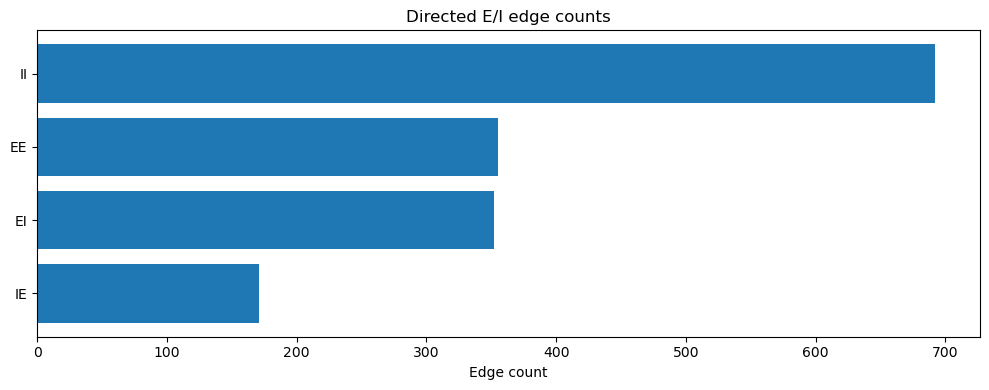

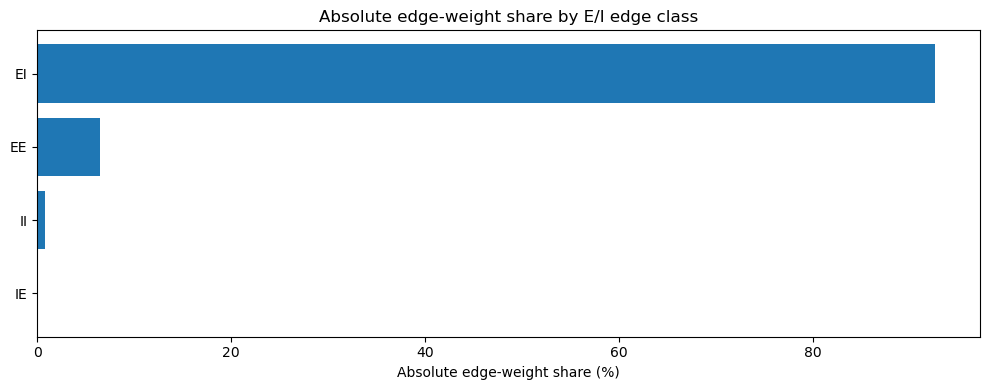

In [7]:

# Baseline edge-class summary before chain enumeration.
edge_class_summary = (
    edges.groupby("edge_signature", as_index=False)
    .agg(
        edge_count=("edge_signature", "size"),
        abs_edge_weight=("abs_weight", "sum"),
        signed_edge_weight=("weight", "sum"),
    )
)
edge_class_summary["edge_count_pct"] = (
    100 * edge_class_summary["edge_count"] / edge_class_summary["edge_count"].sum()
)
edge_class_summary["abs_edge_weight_pct"] = (
    100 * edge_class_summary["abs_edge_weight"] / edge_class_summary["abs_edge_weight"].sum()
)

display(edge_class_summary.sort_values("edge_signature"))

barh(
    edge_class_summary,
    "edge_signature",
    "edge_count",
    "Directed E/I edge counts",
    "Edge count",
    filename="00_edge_class_counts",
)
barh(
    edge_class_summary,
    "edge_signature",
    "abs_edge_weight_pct",
    "Absolute edge-weight share by E/I edge class",
    "Absolute edge-weight share (%)",
    filename="01_edge_class_weight_share",
)


## 4. Enumerate all 3-node directed chains

In [8]:

chains = enumerate_3node_chains(edges, simple_only=SIMPLE_CHAINS_ONLY)

print(f"Enumerated chains: {len(chains):,}")
print(f"Unique node pathways: {chains['node_pathway'].nunique():,}")
print(f"Unique region pathways: {chains['region_pathway'].nunique():,}")
print(f"Unique collapsed-cell-type pathways: {chains['cell_type_pathway'].nunique():,}")

display(
    chains[
        [
            "node_pathway", "signature", "w_12", "w_23",
            "signed_chain_weight", "abs_chain_weight",
            "intensity_geomean", "region_pathway", "layer_pathway",
            "region_layer_pathway", "cell_type_pathway"
        ]
    ].head(20)
)


Enumerated chains: 28,037
Unique node pathways: 28,037
Unique region pathways: 230
Unique collapsed-cell-type pathways: 19,402


,node_pathway,signature,w_12,w_23,signed_chain_weight,abs_chain_weight,intensity_geomean,region_pathway,layer_pathway,region_layer_pathway,cell_type_pathway
0,CA1 Axo Axonic → CA1 Pyramidal → CA1 Back Proj...,IEI,-6.503272,13696.703682,-89073.384685,89073.384685,298.451645,CA1 → CA1 → CA1,Unspecified → Unspecified → Unspecified,CA1:Unspecified → CA1:Unspecified → CA1:Unspec...,Axo Axonic → Pyramidal → Back Projection
1,CA1 Axo Axonic → CA1 Pyramidal → CA1 Basket,IEI,-6.503272,7061.742022,-45924.426652,45924.426652,214.299852,CA1 → CA1 → CA1,Unspecified → Unspecified → Unspecified,CA1:Unspecified → CA1:Unspecified → CA1:Unspec...,Axo Axonic → Pyramidal → Basket
2,CA1 Axo Axonic → CA1 Pyramidal → CA1 Basket CCK+,IEI,-6.503272,6573.981003,-42752.384248,42752.384248,206.766497,CA1 → CA1 → CA1,Unspecified → Unspecified → Unspecified,CA1:Unspecified → CA1:Unspecified → CA1:Unspec...,Axo Axonic → Pyramidal → Basket CCK+
3,CA1 Axo Axonic → CA1 Pyramidal → CA1 Bistratified,IEI,-6.503272,6747.331038,-43879.726617,43879.726617,209.474883,CA1 → CA1 → CA1,Unspecified → Unspecified → Unspecified,CA1:Unspecified → CA1:Unspecified → CA1:Unspec...,Axo Axonic → Pyramidal → Bistratified
4,CA1 Axo Axonic → CA1 Pyramidal → CA1 Horizonta...,IEI,-6.503272,11541.441607,-75057.129941,75057.129941,273.965563,CA1 → CA1 → CA1,Unspecified → Unspecified → Unspecified,CA1:Unspecified → CA1:Unspecified → CA1:Unspec...,Axo Axonic → Pyramidal → Horizontal Axo Axonic
5,CA1 Axo Axonic → CA1 Pyramidal → CA1 Horizonta...,IEI,-6.503272,17544.242040,-114094.971790,114094.971790,337.779472,CA1 → CA1 → CA1,Unspecified → Unspecified → Unspecified,CA1:Unspecified → CA1:Unspecified → CA1:Unspec...,Axo Axonic → Pyramidal → Horizontal Basket
6,CA1 Axo Axonic → CA1 Pyramidal → CA1 Ivy,IEI,-6.503272,3436.355407,-22347.552677,22347.552677,149.490979,CA1 → CA1 → CA1,Unspecified → Unspecified → Unspecified,CA1:Unspecified → CA1:Unspecified → CA1:Unspec...,Axo Axonic → Pyramidal → Ivy
7,CA1 Axo Axonic → CA1 Pyramidal → CA1 O LM,IEI,-6.503272,2791.715371,-18155.283411,18155.283411,134.741543,CA1 → CA1 → CA1,Unspecified → Unspecified → Unspecified,CA1:Unspecified → CA1:Unspecified → CA1:Unspec...,Axo Axonic → Pyramidal → O LM
8,CA1 Axo Axonic → CA1 Pyramidal → CA1 O LMR,IEI,-6.503272,3039.925395,-19769.460625,19769.460625,140.603914,CA1 → CA1 → CA1,Unspecified → Unspecified → Unspecified,CA1:Unspecified → CA1:Unspecified → CA1:Unspec...,Axo Axonic → Pyramidal → O LMR
9,CA1 Axo Axonic → CA1 Pyramidal → CA1 OR LM,IEI,-6.503272,9137.956267,-59426.611881,59426.611881,243.775741,CA1 → CA1 → CA1,Unspecified → Unspecified → Unspecified,CA1:Unspecified → CA1:Unspecified → CA1:Unspec...,Axo Axonic → Pyramidal → OR LM


## 5. E/I signature statistics

In [9]:

sig = signature_summary(chains)
display(sig)

sig.to_csv(OUTPUT_DIR / "ei_signature_summary.csv", index=False)


,signature,chain_count,abs_chain_weight,signed_chain_weight,mean_abs_chain_weight,median_abs_chain_weight,mean_intensity,median_intensity,chain_count_pct,abs_chain_weight_pct,signed_to_abs_ratio
0,EEE,4224,1.846049e+10,1.846049e+10,4.370382e+06,68361.502259,789.607148,261.460276,15.065806,7.917304,1.0
1,EEI,2940,1.796373e+11,1.796373e+11,6.110114e+07,793125.286381,3519.691382,890.574342,10.486143,77.042547,1.0
2,EIE,1217,3.652728e+09,-3.652728e+09,3.001420e+06,39808.365647,632.706835,199.520339,4.340693,1.566576,-1.0
3,EII,4150,2.134710e+10,-2.134710e+10,5.143880e+06,89290.586337,1038.903213,298.815286,14.801869,9.155308,-1.0
4,IEE,1238,3.877988e+08,-3.877988e+08,3.132462e+05,19720.990080,296.829190,140.431441,4.415594,0.166318,-1.0
5,IEI,3258,9.490820e+09,-9.490820e+09,2.913082e+06,43464.449172,717.542803,208.481241,11.620359,4.070406,-1.0
6,IIE,1805,2.225534e+07,2.225534e+07,1.232983e+04,198.093308,47.820013,14.074562,6.437921,0.009545,1.0
7,III,9205,1.678702e+08,1.678702e+08,1.823685e+04,726.295000,65.752376,26.949861,32.831615,0.071996,1.0


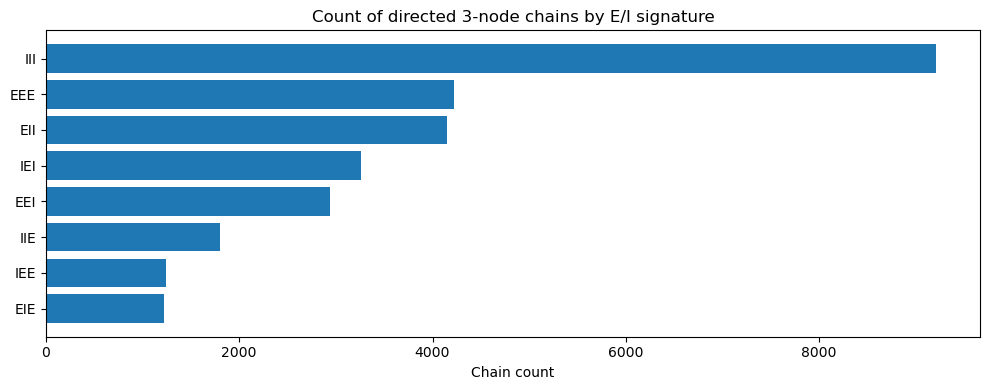

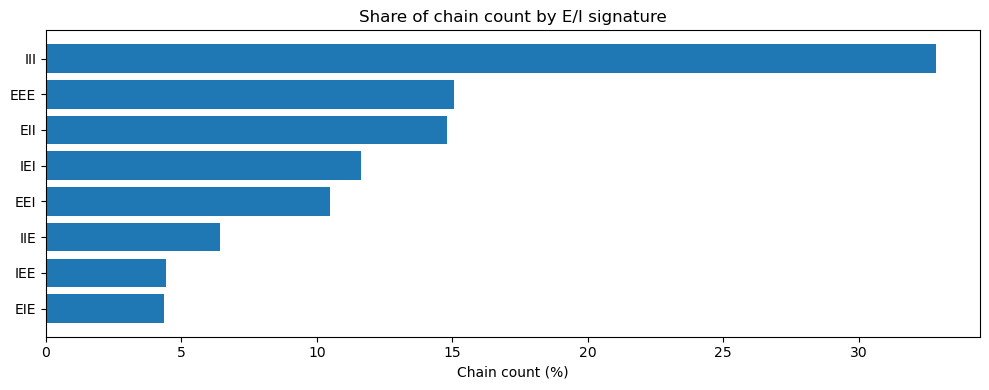

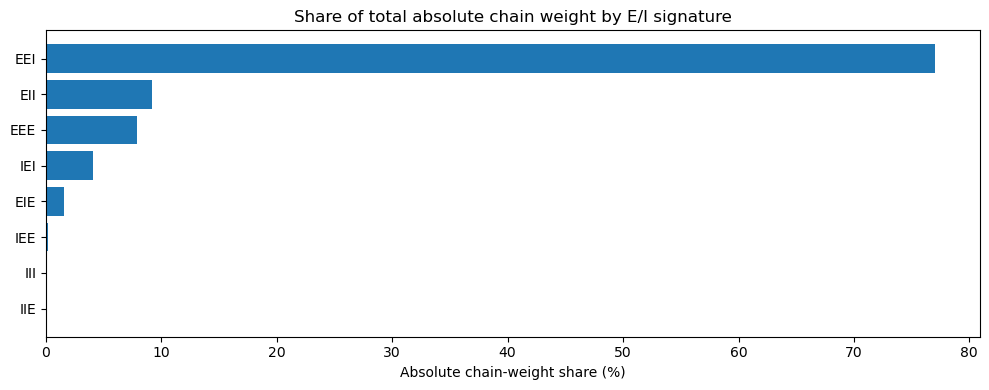

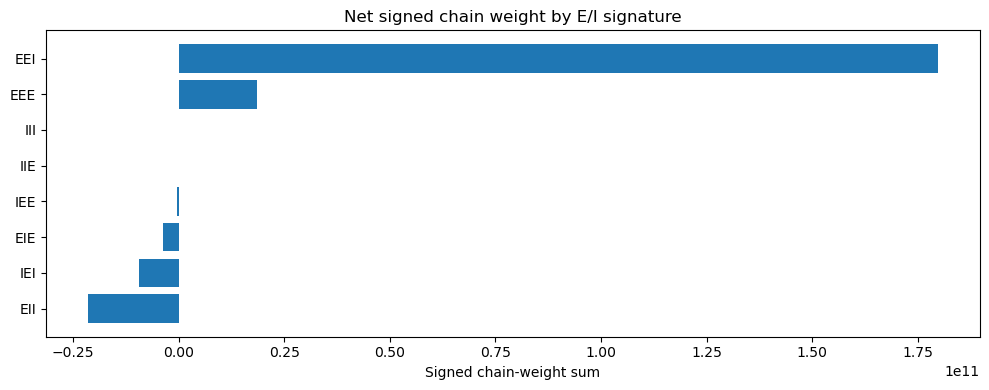

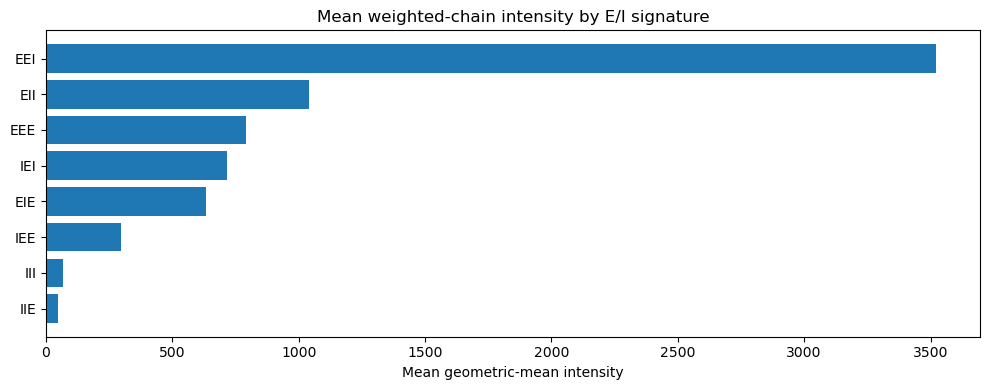

In [10]:

barh(
    sig,
    "signature",
    "chain_count",
    "Count of directed 3-node chains by E/I signature",
    "Chain count",
    filename="02_signature_chain_count",
)

barh(
    sig,
    "signature",
    "chain_count_pct",
    "Share of chain count by E/I signature",
    "Chain count (%)",
    filename="03_signature_chain_count_pct",
)

barh(
    sig,
    "signature",
    "abs_chain_weight_pct",
    "Share of total absolute chain weight by E/I signature",
    "Absolute chain-weight share (%)",
    filename="04_signature_abs_weight_pct",
)

barh(
    sig,
    "signature",
    "signed_chain_weight",
    "Net signed chain weight by E/I signature",
    "Signed chain-weight sum",
    filename="05_signature_signed_weight",
)

barh(
    sig,
    "signature",
    "mean_intensity",
    "Mean weighted-chain intensity by E/I signature",
    "Mean geometric-mean intensity",
    filename="06_signature_mean_intensity",
)



### How to read the signature summary

- `chain_count_pct`: structural prevalence of the signature.
- `abs_chain_weight_pct`: how much of total two-edge coupling strength is carried by that signature.
- `signed_chain_weight`: direction of the net multiplicative effect after preserving signs.
- `signed_to_abs_ratio`: ranges from approximately `-1` to `+1`; values near zero indicate substantial cancellation among signed chain products.
- `mean_intensity`: typical weighted strength of chains in that signature, independent of how many chains exist.

A signature can therefore be **rare but strong**, **common but weak**, or both common and strong.


## 6. Region composition

In [11]:

participation = expand_node_participation(chains)

sig_region = composition_summary(participation, "region")
overall_region = overall_participation_summary(participation, "region")
region_paths = pathway_summary(chains, "region_pathway")
sig_region_paths = signature_pathway_summary(chains, "region_pathway")

display(overall_region)
display(sig_region.head(50))
display(region_paths.head(TOP_N_PATHWAYS))

overall_region.to_csv(OUTPUT_DIR / "region_participation_overall.csv", index=False)
sig_region.to_csv(OUTPUT_DIR / "region_composition_by_signature.csv", index=False)
region_paths.to_csv(OUTPUT_DIR / "region_pathway_summary.csv", index=False)
sig_region_paths.to_csv(OUTPUT_DIR / "region_pathways_by_signature.csv", index=False)


,region,node_occurrences,unique_populations,abs_chain_weight_allocated,signed_chain_weight_allocated,occurrence_pct,weight_pct
0,CA1,36896,28,6.690287e+10,3.738394e+10,43.865844,28.693186
1,CA3c,2375,1,4.185666e+10,3.104112e+10,2.823650,17.951410
2,DG,11031,14,3.146364e+10,2.230026e+10,13.114813,13.494070
3,CA3,9450,13,3.066995e+10,1.831582e+10,11.235154,13.153673
4,EC,8798,9,2.160467e+10,2.021534e+10,10.459987,9.265771
5,CA2,4025,5,2.035423e+10,1.711624e+10,4.785343,8.729485
6,MEC,9327,11,1.843398e+10,1.640054e+10,11.088918,7.905933
7,LEC,1310,3,1.057159e+09,1.042984e+09,1.557466,0.453393
8,SUB,899,1,8.232614e+08,-4.067351e+08,1.068826,0.353079


,signature,region,node_occurrences,unique_populations,abs_chain_weight_allocated,signed_chain_weight_allocated,occurrence_pct_within_signature,weight_pct_within_signature
0,EEE,EC,5423,9,5.577379e+09,5.577379e+09,42.795139,30.212511
1,EEE,MEC,4977,9,3.327373e+09,3.327373e+09,39.275568,18.024290
2,EEE,CA1,322,2,2.670755e+09,2.670755e+09,2.541035,14.467408
3,EEE,CA3c,122,1,2.447265e+09,2.447265e+09,0.962753,13.256768
4,EEE,DG,400,4,1.879227e+09,1.879227e+09,3.156566,10.179721
5,EEE,CA3,142,2,9.367877e+08,9.367877e+08,1.120581,5.074554
6,EEE,LEC,1063,3,8.182318e+08,8.182318e+08,8.388573,4.432340
7,EEE,CA2,84,1,6.281710e+08,6.281710e+08,0.662879,3.402786
8,EEE,SUB,139,1,1.753050e+08,1.753050e+08,1.096907,0.949622
9,EEI,CA1,1589,28,4.937628e+10,4.937628e+10,18.015873,27.486644


,region_pathway,chain_count,abs_chain_weight,signed_chain_weight,mean_intensity,chain_count_pct,abs_chain_weight_pct
0,CA3 → CA3c → CA1,338,3.921893e+10,3.165851e+10,4049.825875,1.205550,16.820144
1,CA3c → CA1 → CA1,458,2.707702e+10,1.084914e+10,3702.395696,1.633556,11.612743
2,CA2 → CA3c → CA1,52,1.232336e+10,1.081519e+10,10974.325811,0.185469,5.285221
3,CA3c → CA2 → CA1,62,1.187275e+10,1.143527e+10,8257.279138,0.221136,5.091962
4,DG → CA3c → CA1,104,1.046112e+10,1.045972e+10,5308.080114,0.370938,4.486548
5,MEC → CA3 → CA1,26,9.783786e+09,9.783786e+09,14169.039436,0.092735,4.196053
6,EC → EC → MEC,333,8.531221e+09,8.531221e+09,1735.629225,1.187716,3.658855
7,CA3 → CA1 → CA1,929,8.032817e+09,-3.123387e+09,1143.268322,3.313479,3.445100
8,MEC → DG → DG,219,7.996889e+09,7.611918e+09,1993.325302,0.781111,3.429692
9,DG → DG → DG,1226,7.558965e+09,5.120569e+08,834.445780,4.372793,3.241875


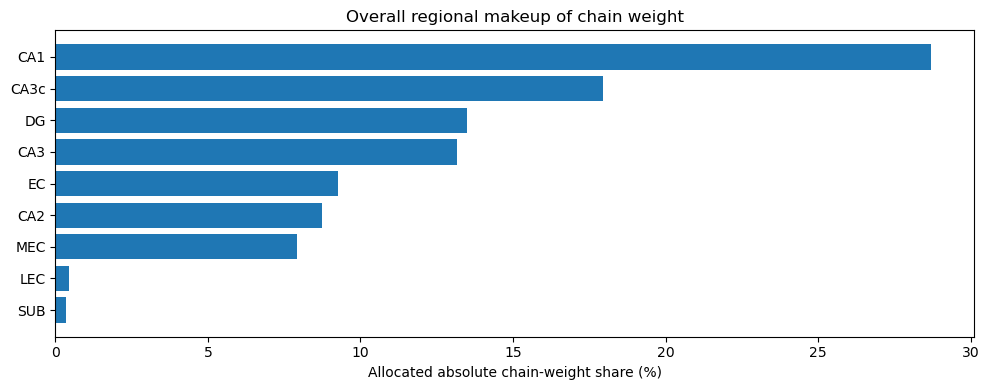

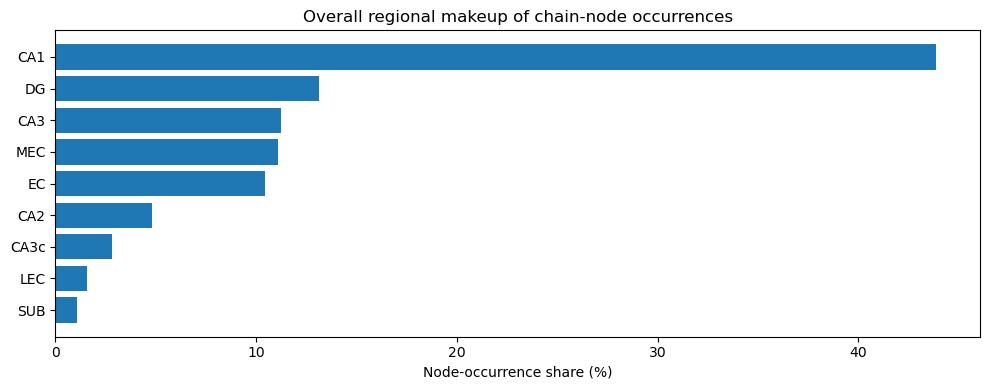

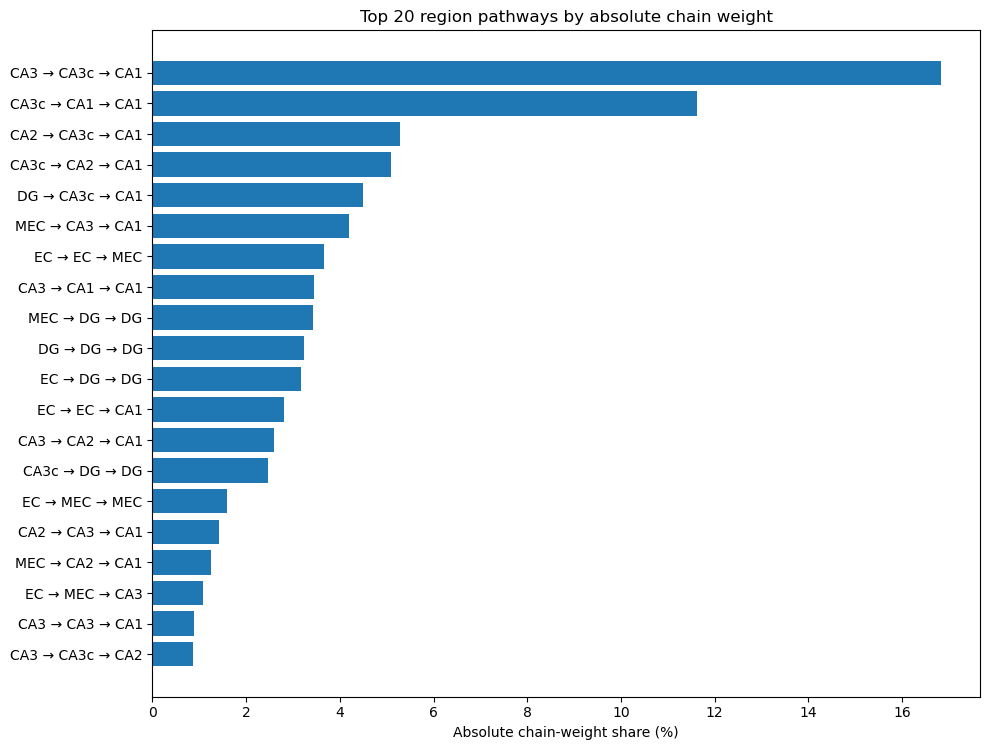

In [12]:

barh(
    overall_region,
    "region",
    "weight_pct",
    "Overall regional makeup of chain weight",
    "Allocated absolute chain-weight share (%)",
    filename="07_overall_region_weight_share",
)

barh(
    overall_region,
    "region",
    "occurrence_pct",
    "Overall regional makeup of chain-node occurrences",
    "Node-occurrence share (%)",
    filename="08_overall_region_occurrence_share",
)

barh(
    region_paths,
    "region_pathway",
    "abs_chain_weight_pct",
    f"Top {TOP_N_PATHWAYS} region pathways by absolute chain weight",
    "Absolute chain-weight share (%)",
    filename="09_top_region_pathways",
    top_n=TOP_N_PATHWAYS,
)


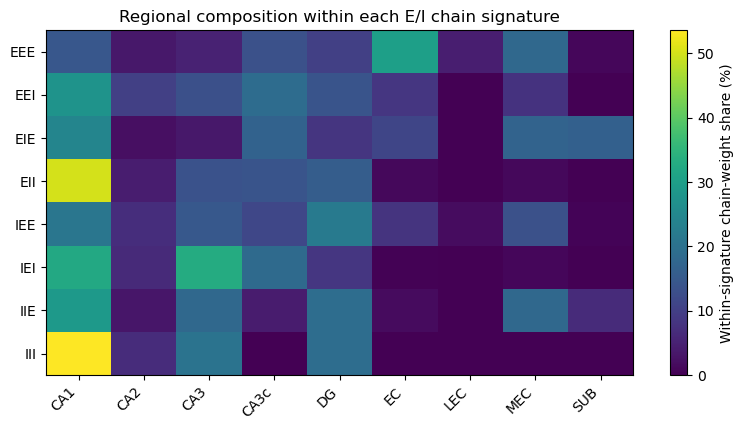

In [13]:

# Heatmap: within each E/I signature, what percentage of allocated chain weight
# is associated with each region?
region_heat = (
    sig_region.pivot(
        index="signature",
        columns="region",
        values="weight_pct_within_signature",
    )
    .reindex(SIGNATURE_ORDER)
    .fillna(0)
)

heatmap_from_pivot(
    region_heat,
    "Regional composition within each E/I chain signature",
    "Within-signature chain-weight share (%)",
    filename="10_signature_region_heatmap",
)


## 7. Cell-type composition regardless of region

In [14]:

sig_cell = composition_summary(participation, "cell_type")
overall_cell = overall_participation_summary(participation, "cell_type")
cell_paths = pathway_summary(chains, "cell_type_pathway")
sig_cell_paths = signature_pathway_summary(chains, "cell_type_pathway")

display(overall_cell.head(50))
display(sig_cell.head(100))
display(cell_paths.head(TOP_N_PATHWAYS))

overall_cell.to_csv(OUTPUT_DIR / "cell_type_participation_overall.csv", index=False)
sig_cell.to_csv(OUTPUT_DIR / "cell_type_composition_by_signature.csv", index=False)
cell_paths.to_csv(OUTPUT_DIR / "cell_type_pathway_summary.csv", index=False)
sig_cell_paths.to_csv(OUTPUT_DIR / "cell_type_pathways_by_signature.csv", index=False)


,cell_type,node_occurrences,unique_populations,abs_chain_weight_allocated,signed_chain_weight_allocated,occurrence_pct,weight_pct
0,Pyramidal,10865,6,9.886837e+10,7.934207e+10,12.917454,42.402490
1,Granule,1706,2,1.522784e+10,1.288890e+10,2.028272,6.530889
2,Trilaminar,2443,2,9.545244e+09,5.052860e+09,2.904495,4.093747
3,Multipolar Pyramidal,1728,3,9.058087e+09,8.424977e+09,2.054428,3.884817
4,Stellate,1948,2,8.322312e+09,7.966765e+09,2.315987,3.569258
5,Perforant Path Associated QuadD,1130,1,7.205934e+09,4.910834e+09,1.343463,3.090468
6,Basket,2542,4,6.829497e+09,2.248169e+09,3.022197,2.929023
7,Perforant Path Associated,1540,1,5.954713e+09,2.838500e+09,1.830914,2.553847
8,Axo Axonic,1888,3,5.432363e+09,3.743127e+09,2.244653,2.329822
9,Basket CCK+,1679,2,4.881143e+09,-6.871538e+08,1.996172,2.093416


,signature,cell_type,node_occurrences,unique_populations,abs_chain_weight_allocated,signed_chain_weight_allocated,occurrence_pct_within_signature,weight_pct_within_signature
0,EEE,Pyramidal,1999,6,7.129668e+09,7.129668e+09,15.774937,38.621220
1,EEE,Multipolar Pyramidal,1261,3,2.688278e+09,2.688278e+09,9.951073,14.562329
2,EEE,Stellate,1075,2,1.216623e+09,1.216623e+09,8.483270,6.590414
3,EEE,Granule,165,2,1.176293e+09,1.176293e+09,1.302083,6.371946
4,EEE,Pyramidal Fan,562,1,9.757195e+08,9.757195e+08,4.434975,5.285446
5,EEE,Pyramidal Tripolar,780,1,8.847963e+08,8.847963e+08,6.155303,4.792918
6,EEE,Pyramidal Polymorphic,177,1,5.595122e+08,5.595122e+08,1.396780,3.030863
7,EEE,Mossy,51,1,5.467413e+08,5.467413e+08,0.402462,2.961683
8,EEE,Complex Pyramidal,1039,2,4.640276e+08,4.640276e+08,8.199179,2.513625
9,EEE,Hilar Ectopic Granule,116,1,3.610862e+08,3.610862e+08,0.915404,1.955994


,cell_type_pathway,chain_count,abs_chain_weight,signed_chain_weight,mean_intensity,chain_count_pct,abs_chain_weight_pct
0,Pyramidal → Pyramidal → Trilaminar,16,1.504222e+10,1.504222e+10,21424.934983,0.057067,6.451280
1,Pyramidal → Pyramidal → Perforant Path Associa...,11,1.328888e+10,1.328888e+10,26141.921750,0.039234,5.699313
2,Pyramidal → Pyramidal → Perforant Path Associated,7,9.198250e+09,9.198250e+09,27281.541478,0.024967,3.944929
3,Pyramidal → Pyramidal → R Receiving Apical Tar...,6,7.399025e+09,7.399025e+09,29576.715734,0.021400,3.173281
4,Pyramidal → Pyramidal → Basket,29,6.913206e+09,6.913206e+09,11374.993319,0.103435,2.964923
5,Pyramidal → Pyramidal → OR LM,10,5.445254e+09,5.445254e+09,18624.987401,0.035667,2.335351
6,Stellate → Pyramidal → Trilaminar,4,5.371339e+09,5.371339e+09,24234.835286,0.014267,2.303650
7,Pyramidal → Pyramidal → Basket CCK+,17,4.340820e+09,4.340820e+09,10253.770272,0.060634,1.861683
8,Pyramidal → Pyramidal → Bistratified,16,4.149025e+09,4.149025e+09,13028.469303,0.057067,1.779427
9,Pyramidal → Granule → AIPRIM,2,3.751296e+09,3.751296e+09,43195.722411,0.007133,1.608849


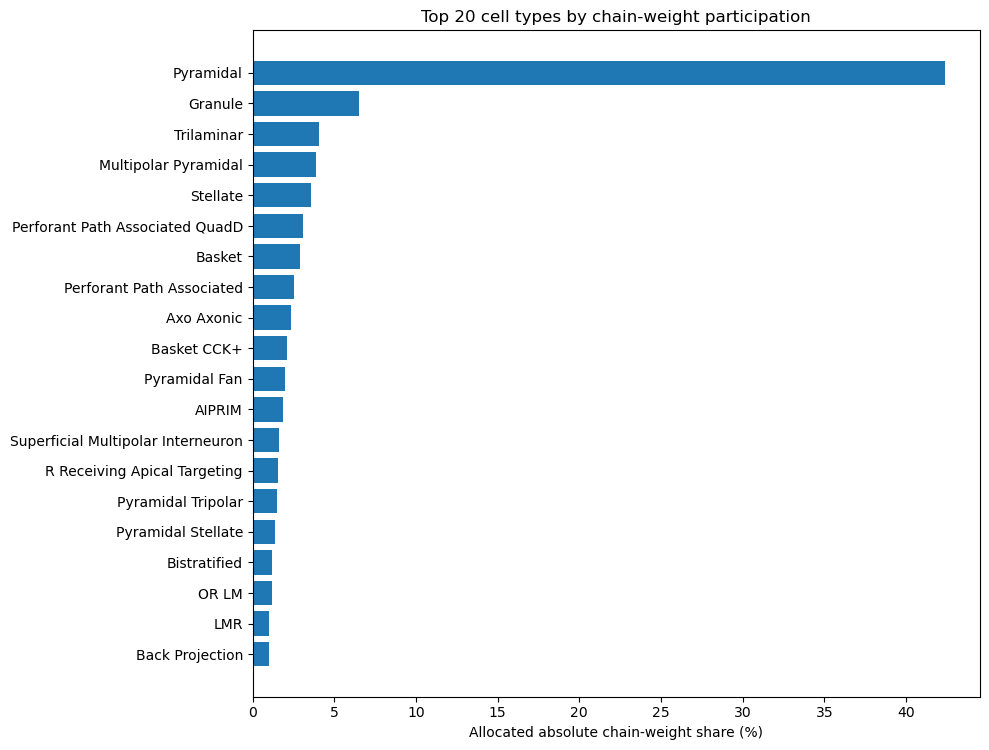

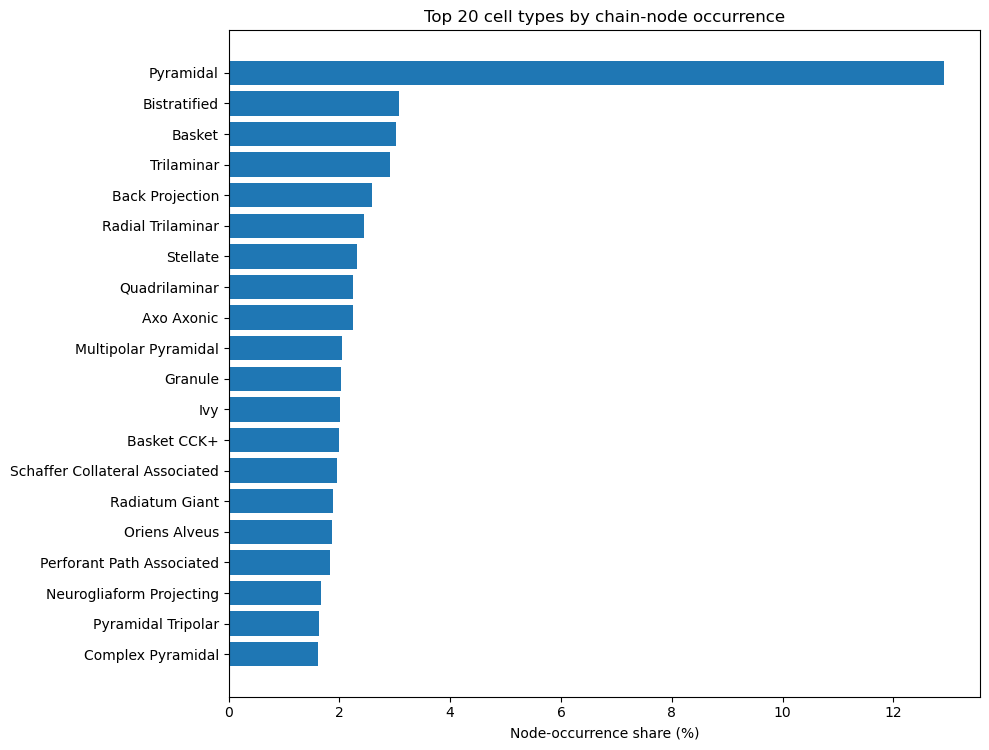

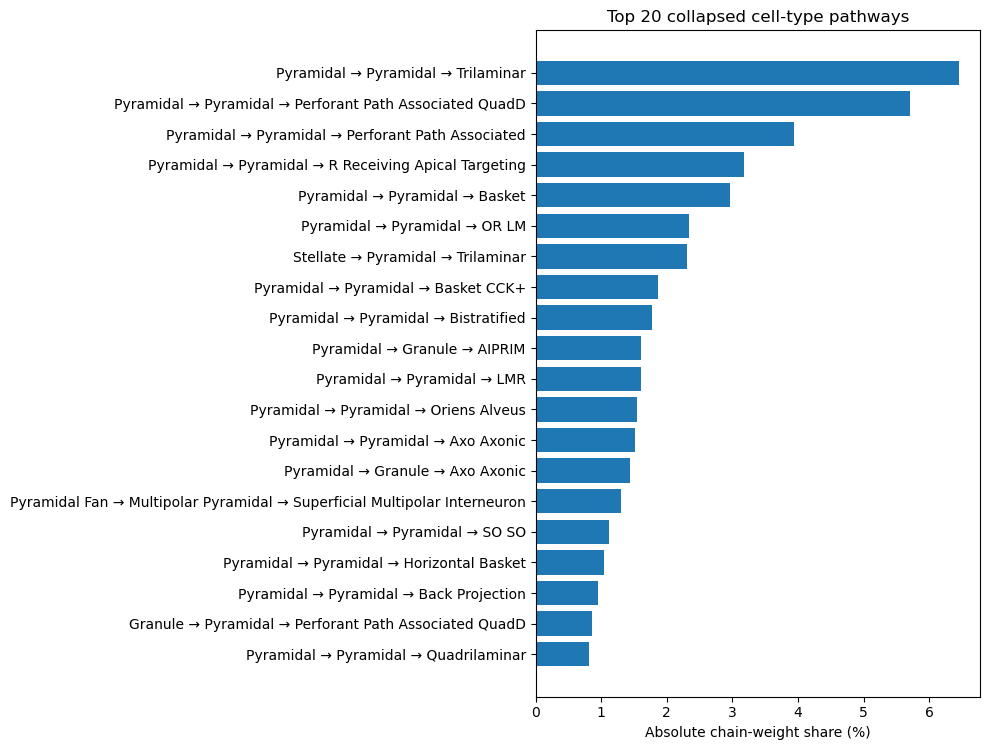

In [15]:

barh(
    overall_cell,
    "cell_type",
    "weight_pct",
    f"Top {TOP_N_CELL_TYPES} cell types by chain-weight participation",
    "Allocated absolute chain-weight share (%)",
    filename="11_top_cell_types_weight_share",
    top_n=TOP_N_CELL_TYPES,
)

barh(
    overall_cell,
    "cell_type",
    "occurrence_pct",
    f"Top {TOP_N_CELL_TYPES} cell types by chain-node occurrence",
    "Node-occurrence share (%)",
    filename="12_top_cell_types_occurrence_share",
    top_n=TOP_N_CELL_TYPES,
)

barh(
    cell_paths,
    "cell_type_pathway",
    "abs_chain_weight_pct",
    f"Top {TOP_N_PATHWAYS} collapsed cell-type pathways",
    "Absolute chain-weight share (%)",
    filename="13_top_cell_type_pathways",
    top_n=TOP_N_PATHWAYS,
)


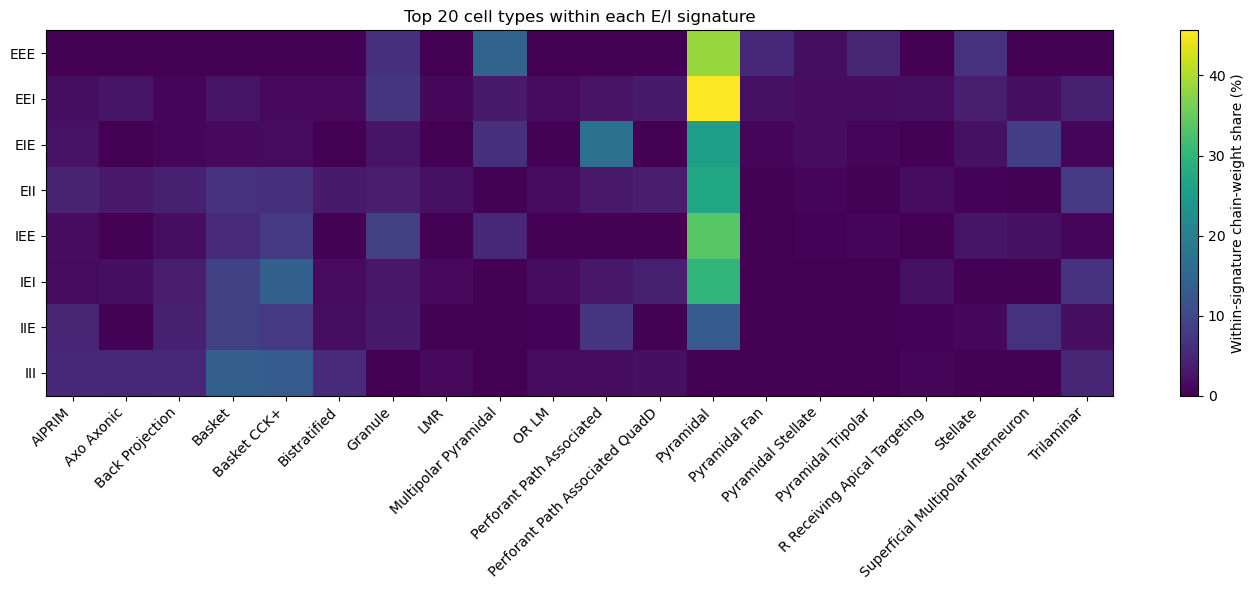

In [16]:

# Choose the globally strongest cell types, then show their contribution
# within every E/I signature.
top_cell_types = overall_cell.head(TOP_N_CELL_TYPES)["cell_type"]

cell_heat = (
    sig_cell[sig_cell["cell_type"].isin(top_cell_types)]
    .pivot(
        index="signature",
        columns="cell_type",
        values="weight_pct_within_signature",
    )
    .reindex(SIGNATURE_ORDER)
    .fillna(0)
)

heatmap_from_pivot(
    cell_heat,
    f"Top {TOP_N_CELL_TYPES} cell types within each E/I signature",
    "Within-signature chain-weight share (%)",
    filename="14_signature_cell_type_heatmap",
    figsize=(max(12, 0.7 * len(cell_heat.columns)), 6),
)


## 8. Region × layer analysis

This section treats the anatomical **region** and cortical/hippocampal **layer** as separate attributes.

Examples:

- `EC LI II Multipolar Pyramidal` contributes to region `EC`, layer `LI-LII`, cell type `Multipolar Pyramidal`.
- `MEC LIII Multipolar Principal` contributes to region `MEC`, layer `LIII`, cell type `Multipolar Principal`.

This makes it possible to ask whether a chain signature is concentrated not merely in a region, but in a specific **region-layer compartment**.


In [17]:

# Overall layer and region-layer participation.
sig_layer = composition_summary(participation, "layer")
overall_layer = overall_participation_summary(participation, "layer")

sig_region_layer = composition_summary(participation, "region_layer")
overall_region_layer = overall_participation_summary(participation, "region_layer")

layer_paths = pathway_summary(chains, "layer_pathway")
region_layer_paths = pathway_summary(chains, "region_layer_pathway")
sig_region_layer_paths = signature_pathway_summary(chains, "region_layer_pathway")

display(overall_layer)
display(overall_region_layer.head(50))
display(region_layer_paths.head(TOP_N_PATHWAYS))

overall_layer.to_csv(OUTPUT_DIR / "layer_participation_overall.csv", index=False)
sig_layer.to_csv(OUTPUT_DIR / "layer_composition_by_signature.csv", index=False)
overall_region_layer.to_csv(OUTPUT_DIR / "region_layer_participation_overall.csv", index=False)
sig_region_layer.to_csv(OUTPUT_DIR / "region_layer_composition_by_signature.csv", index=False)
layer_paths.to_csv(OUTPUT_DIR / "layer_pathway_summary.csv", index=False)
region_layer_paths.to_csv(OUTPUT_DIR / "region_layer_pathway_summary.csv", index=False)
sig_region_layer_paths.to_csv(
    OUTPUT_DIR / "region_layer_pathways_by_signature.csv", index=False
)


,layer,node_occurrences,unique_populations,abs_chain_weight_allocated,signed_chain_weight_allocated,occurrence_pct,weight_pct
0,Unspecified,64676,62,1.920706e+11,1.257506e+11,76.893629,82.374904
1,LI-LII,1798,2,1.307972e+10,1.232092e+10,2.137651,5.609608
2,LIII,7847,9,9.658771e+09,7.755781e+09,9.329339,4.142437
3,LII,1782,2,8.218967e+09,7.884077e+09,2.118629,3.524936
4,LV,3574,4,4.357752e+09,4.166721e+09,4.249147,1.868945
5,LII-LIII,2262,2,3.977080e+09,3.774727e+09,2.689303,1.705683
6,LV-LVI,219,1,5.654896e+08,5.535349e+08,0.260370,0.242526
7,LIII-LV,1005,1,4.413759e+08,4.194188e+08,1.194850,0.189296
8,LVI,342,1,4.191051e+08,4.105928e+08,0.406606,0.179745
9,LIV-LVI,606,1,3.775434e+08,3.730968e+08,0.720477,0.161920


,region_layer,node_occurrences,unique_populations,abs_chain_weight_allocated,signed_chain_weight_allocated,occurrence_pct,weight_pct
0,CA1:Unspecified,36896,28,6.690287e+10,3.738394e+10,43.865844,28.693186
1,CA3c:Unspecified,2375,1,4.185666e+10,3.104112e+10,2.823650,17.951410
2,DG:Unspecified,11031,14,3.146364e+10,2.230026e+10,13.114813,13.494070
3,CA3:Unspecified,9450,13,3.066995e+10,1.831582e+10,11.235154,13.153673
4,CA2:Unspecified,4025,5,2.035423e+10,1.711624e+10,4.785343,8.729485
5,EC:LI-LII,1798,2,1.307972e+10,1.232092e+10,2.137651,5.609608
6,MEC:LII,1782,2,8.218967e+09,7.884077e+09,2.118629,3.524936
7,MEC:LIII,3426,4,5.160725e+09,3.751165e+09,4.073189,2.213323
8,MEC:LV,3007,3,4.047175e+09,3.865444e+09,3.575038,1.735745
9,EC:LIII,3453,3,3.859992e+09,3.372224e+09,4.105289,1.655466


,region_layer_pathway,chain_count,abs_chain_weight,signed_chain_weight,mean_intensity,chain_count_pct,abs_chain_weight_pct
0,CA3:Unspecified → CA3c:Unspecified → CA1:Unspe...,338,3.921893e+10,3.165851e+10,4049.825875,1.205550,16.820144
1,CA3c:Unspecified → CA1:Unspecified → CA1:Unspe...,458,2.707702e+10,1.084914e+10,3702.395696,1.633556,11.612743
2,CA2:Unspecified → CA3c:Unspecified → CA1:Unspe...,52,1.232336e+10,1.081519e+10,10974.325811,0.185469,5.285221
3,CA3c:Unspecified → CA2:Unspecified → CA1:Unspe...,62,1.187275e+10,1.143527e+10,8257.279138,0.221136,5.091962
4,DG:Unspecified → CA3c:Unspecified → CA1:Unspec...,104,1.046112e+10,1.045972e+10,5308.080114,0.370938,4.486548
5,MEC:LII → CA3:Unspecified → CA1:Unspecified,26,9.783786e+09,9.783786e+09,14169.039436,0.092735,4.196053
6,CA3:Unspecified → CA1:Unspecified → CA1:Unspec...,929,8.032817e+09,-3.123387e+09,1143.268322,3.313479,3.445100
7,DG:Unspecified → DG:Unspecified → DG:Unspecified,1226,7.558965e+09,5.120569e+08,834.445780,4.372793,3.241875
8,MEC:LV → DG:Unspecified → DG:Unspecified,116,7.416465e+09,7.056226e+09,2938.456803,0.413739,3.180760
9,CA3:Unspecified → CA2:Unspecified → CA1:Unspec...,102,6.028579e+09,5.869017e+09,3551.286807,0.363805,2.585527


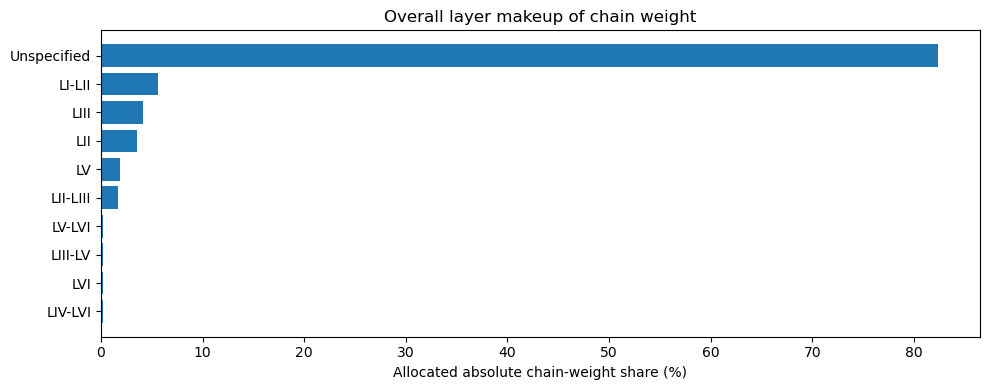

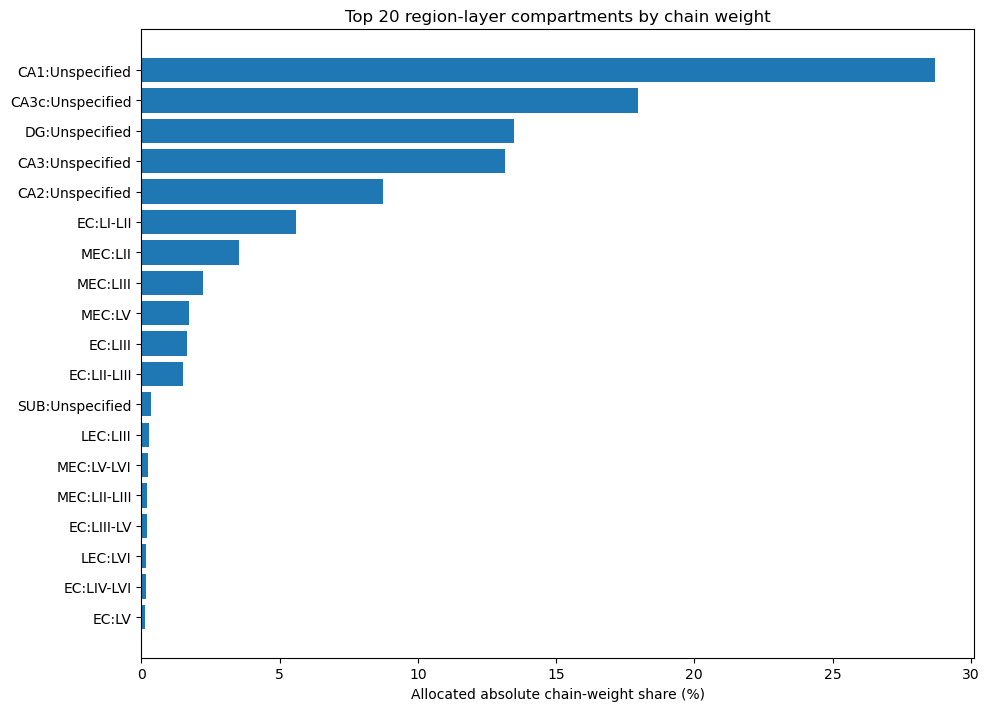

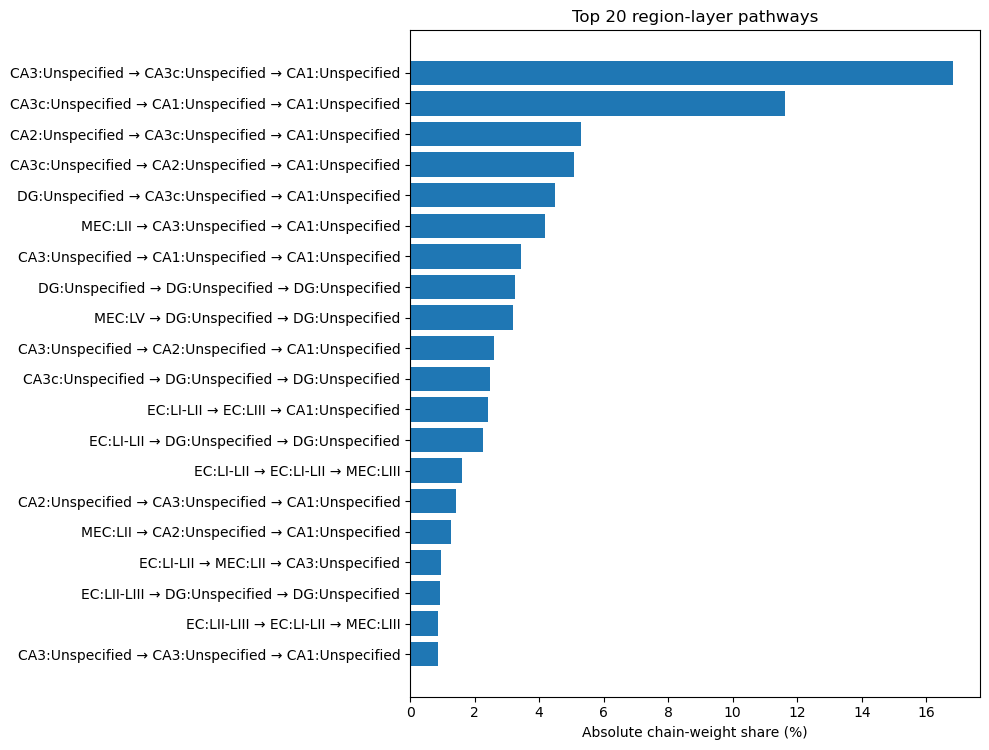

In [18]:

barh(
    overall_layer,
    "layer",
    "weight_pct",
    "Overall layer makeup of chain weight",
    "Allocated absolute chain-weight share (%)",
    filename="17_overall_layer_weight_share",
)

barh(
    overall_region_layer,
    "region_layer",
    "weight_pct",
    f"Top {TOP_N_PATHWAYS} region-layer compartments by chain weight",
    "Allocated absolute chain-weight share (%)",
    filename="18_top_region_layer_weight_share",
    top_n=TOP_N_PATHWAYS,
)

barh(
    region_layer_paths,
    "region_layer_pathway",
    "abs_chain_weight_pct",
    f"Top {TOP_N_PATHWAYS} region-layer pathways",
    "Absolute chain-weight share (%)",
    filename="19_top_region_layer_pathways",
    top_n=TOP_N_PATHWAYS,
)


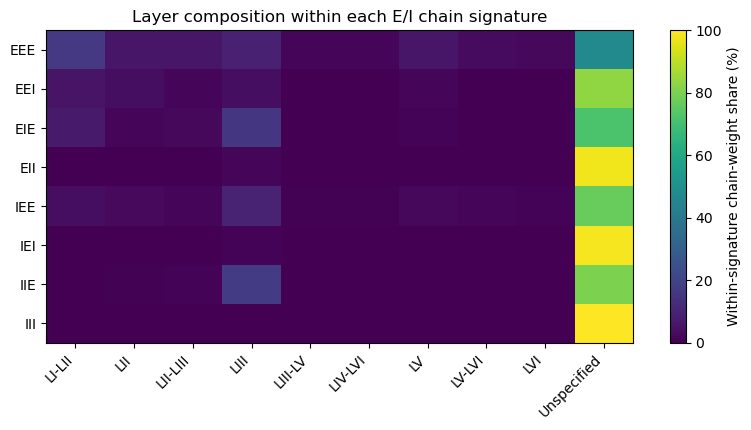

In [19]:

# Heatmap: layer composition within each E/I signature.
layer_heat = (
    sig_layer.pivot(
        index="signature",
        columns="layer",
        values="weight_pct_within_signature",
    )
    .reindex(SIGNATURE_ORDER)
    .fillna(0)
)

heatmap_from_pivot(
    layer_heat,
    "Layer composition within each E/I chain signature",
    "Within-signature chain-weight share (%)",
    filename="20_signature_layer_heatmap",
)


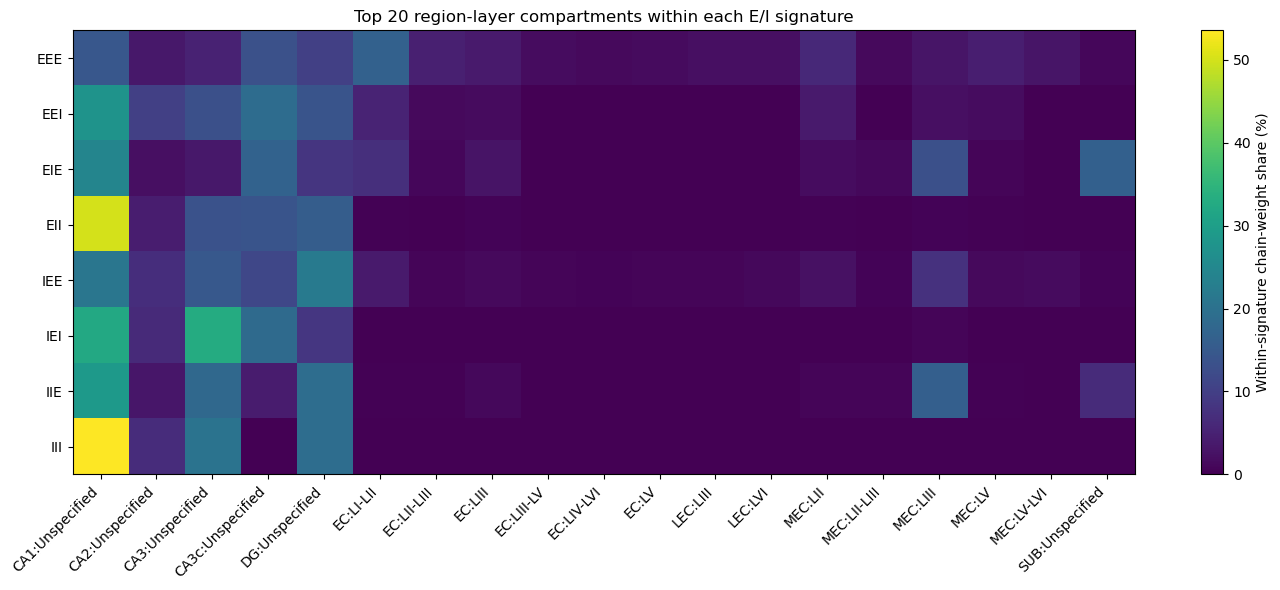

In [20]:

# Heatmap: strongest region-layer compartments within each E/I signature.
top_region_layers = overall_region_layer.head(TOP_N_CELL_TYPES)["region_layer"]

region_layer_heat = (
    sig_region_layer[sig_region_layer["region_layer"].isin(top_region_layers)]
    .pivot(
        index="signature",
        columns="region_layer",
        values="weight_pct_within_signature",
    )
    .reindex(SIGNATURE_ORDER)
    .fillna(0)
)

heatmap_from_pivot(
    region_layer_heat,
    f"Top {TOP_N_CELL_TYPES} region-layer compartments within each E/I signature",
    "Within-signature chain-weight share (%)",
    filename="21_signature_region_layer_heatmap",
    figsize=(max(12, 0.75 * len(region_layer_heat.columns)), 6),
)


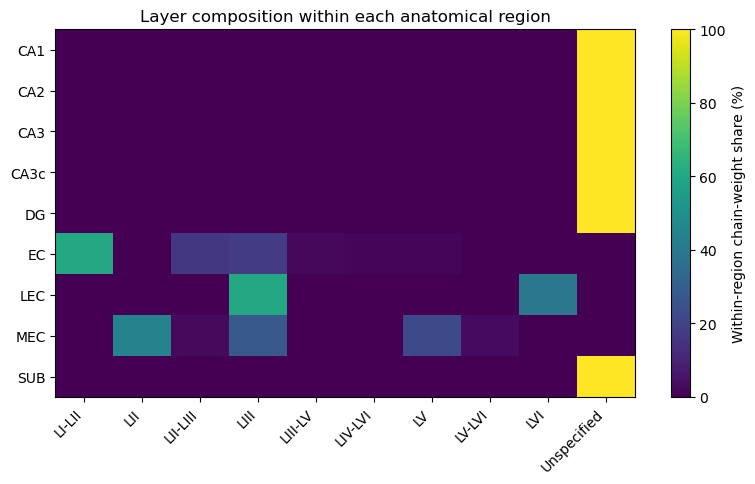

In [21]:

# Region x layer matrix across all chains.
region_layer_matrix = (
    participation.groupby(["region", "layer"], as_index=False)
    ["abs_chain_weight_allocated"].sum()
)

region_layer_pivot = (
    region_layer_matrix.pivot(
        index="region",
        columns="layer",
        values="abs_chain_weight_allocated",
    )
    .fillna(0)
)

# Convert each region to percentages across its own layers.
region_layer_pct = region_layer_pivot.div(
    region_layer_pivot.sum(axis=1).replace(0, np.nan),
    axis=0
) * 100
region_layer_pct = region_layer_pct.fillna(0)

heatmap_from_pivot(
    region_layer_pct,
    "Layer composition within each anatomical region",
    "Within-region chain-weight share (%)",
    filename="22_region_by_layer_heatmap",
)


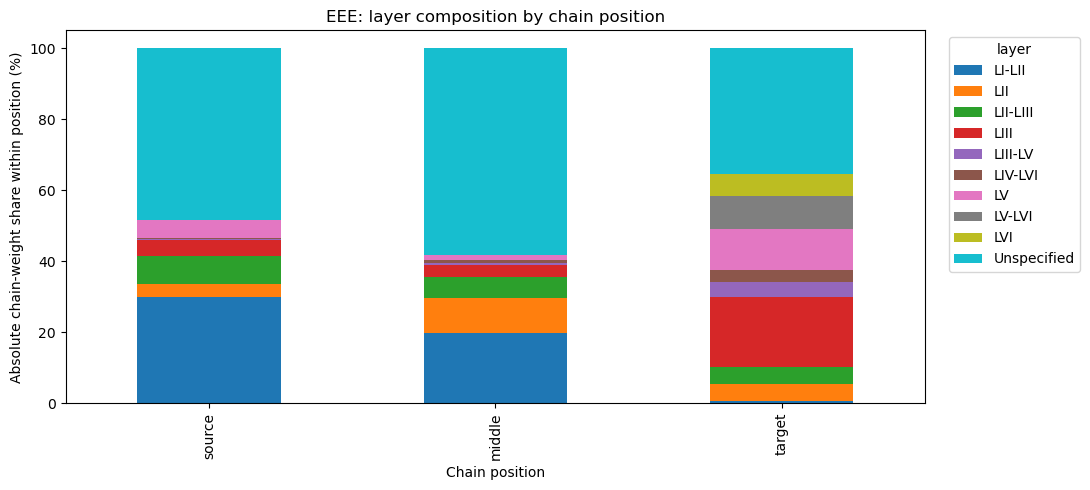

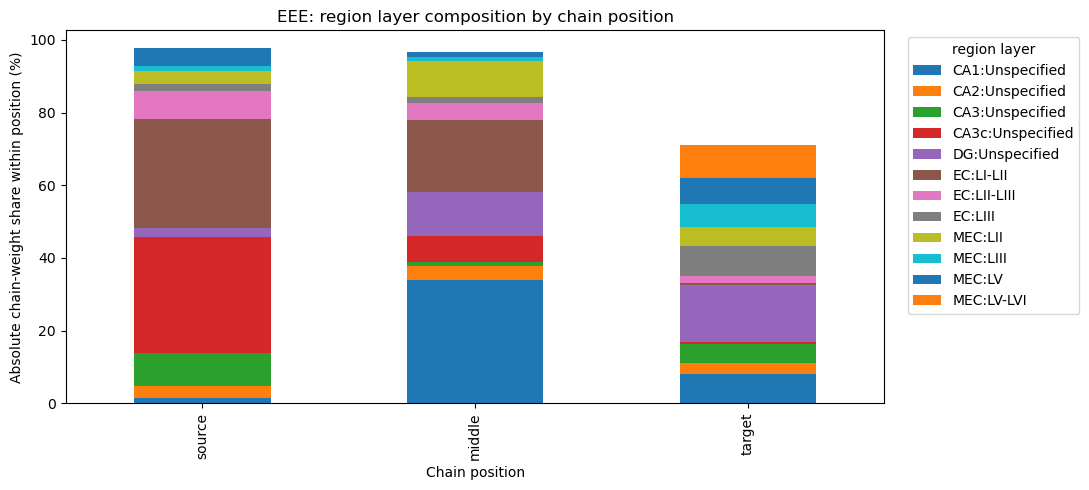

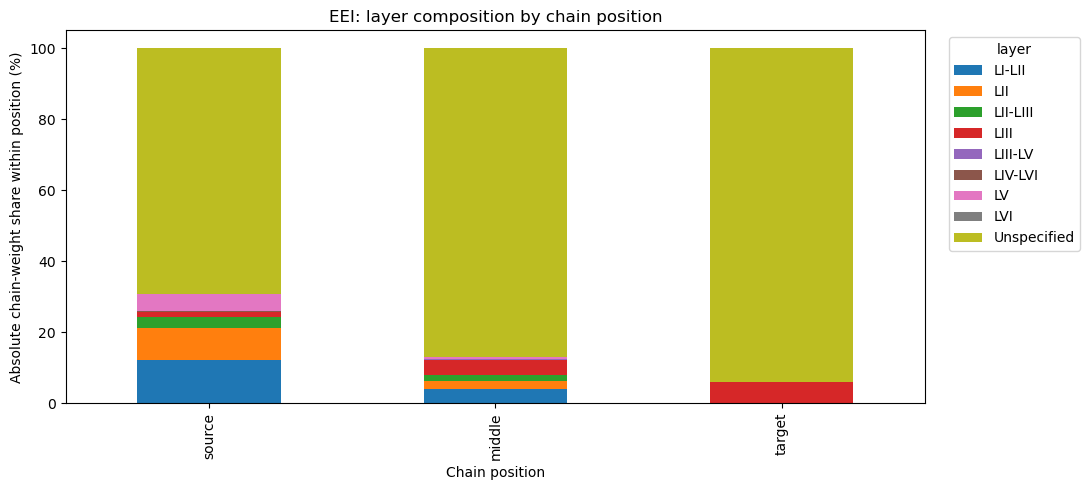

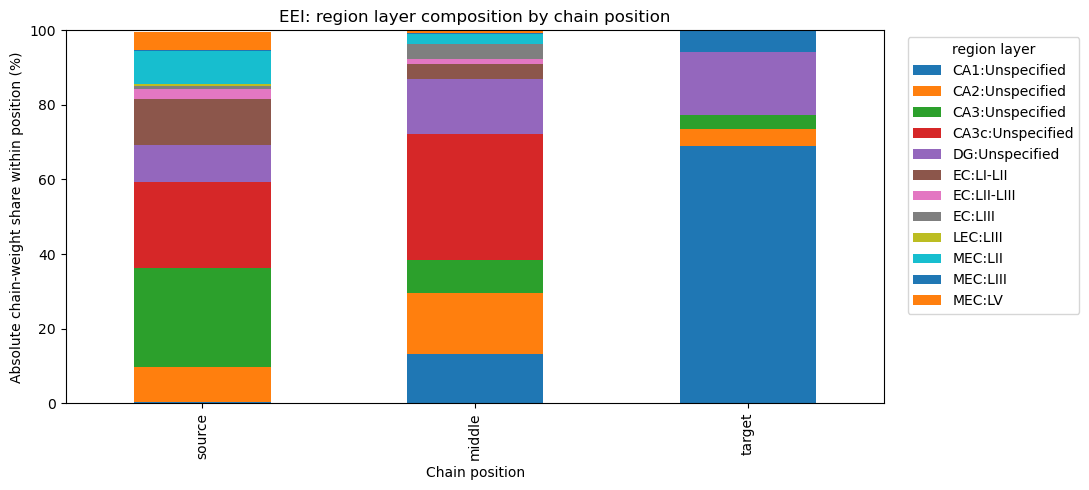

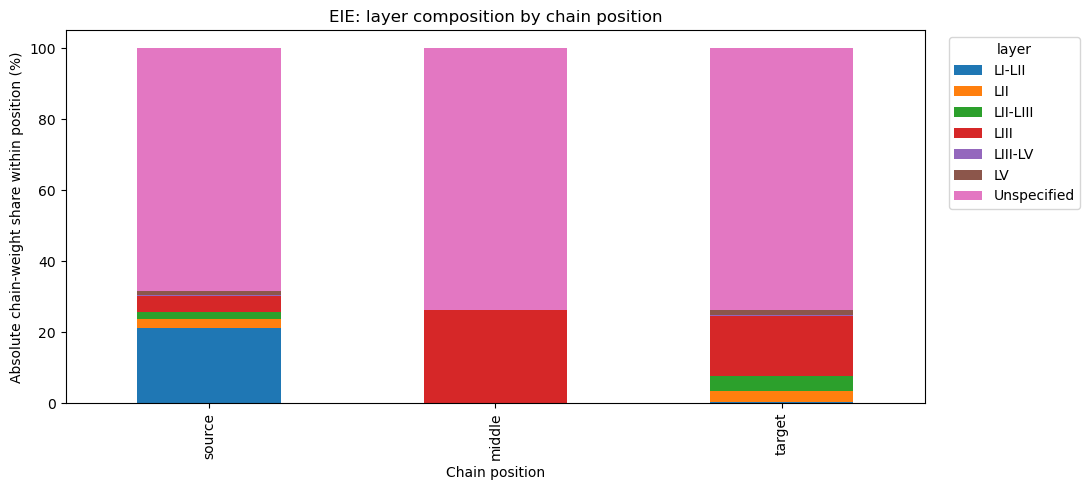

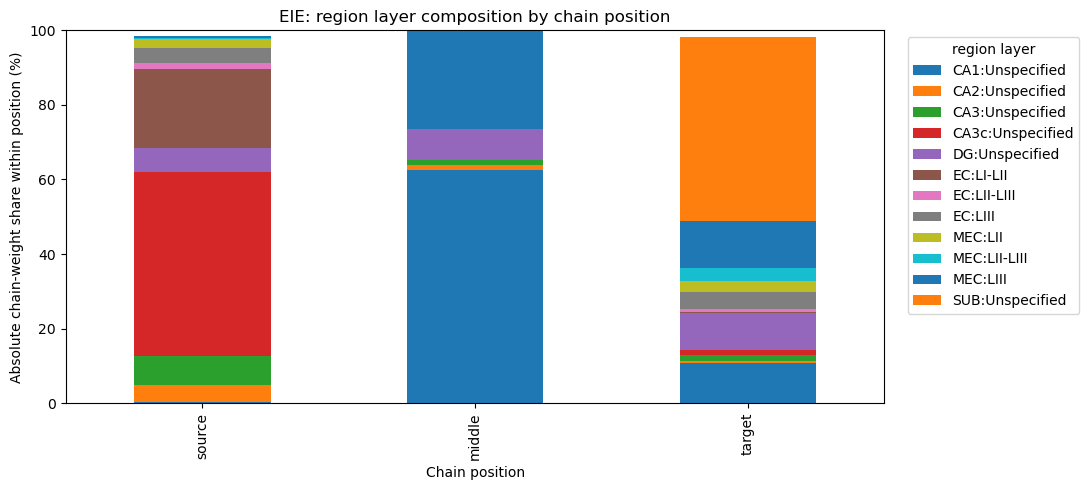

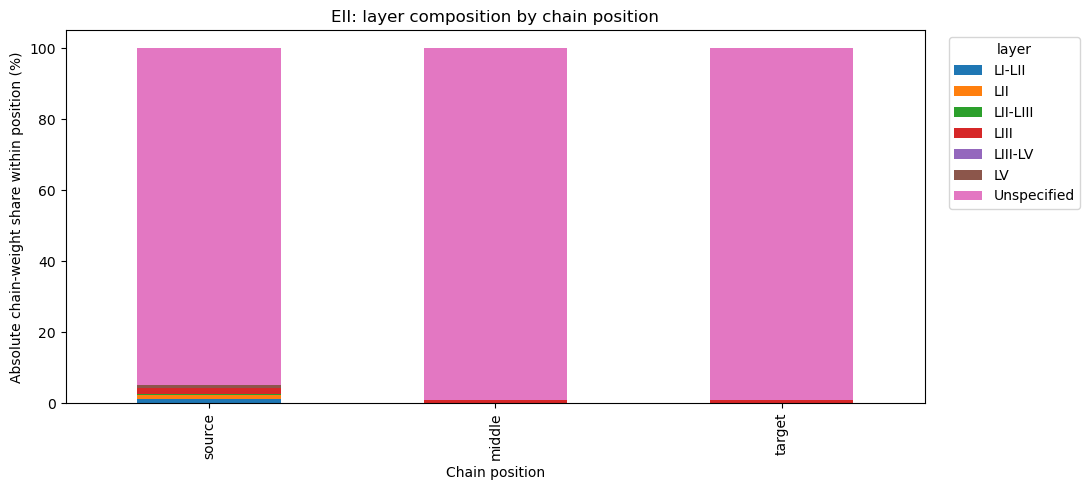

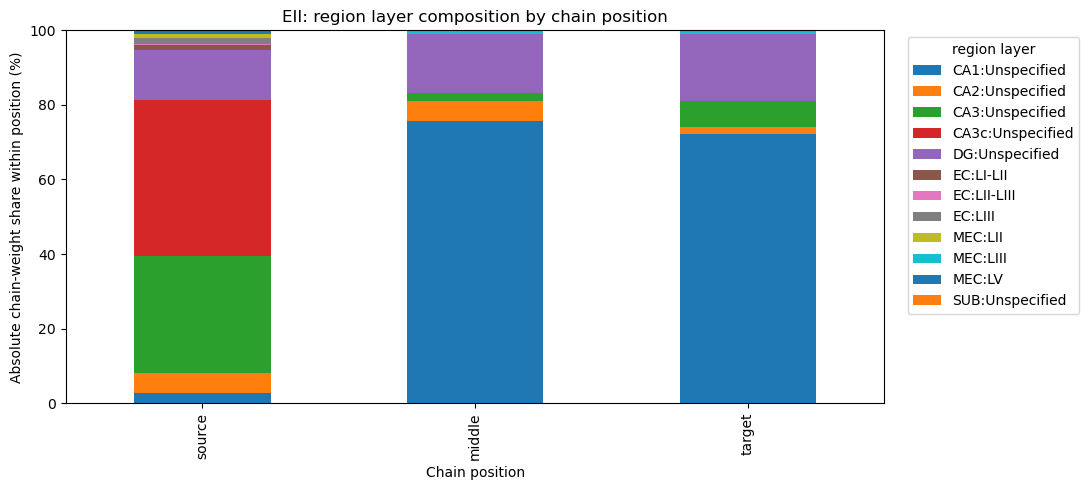

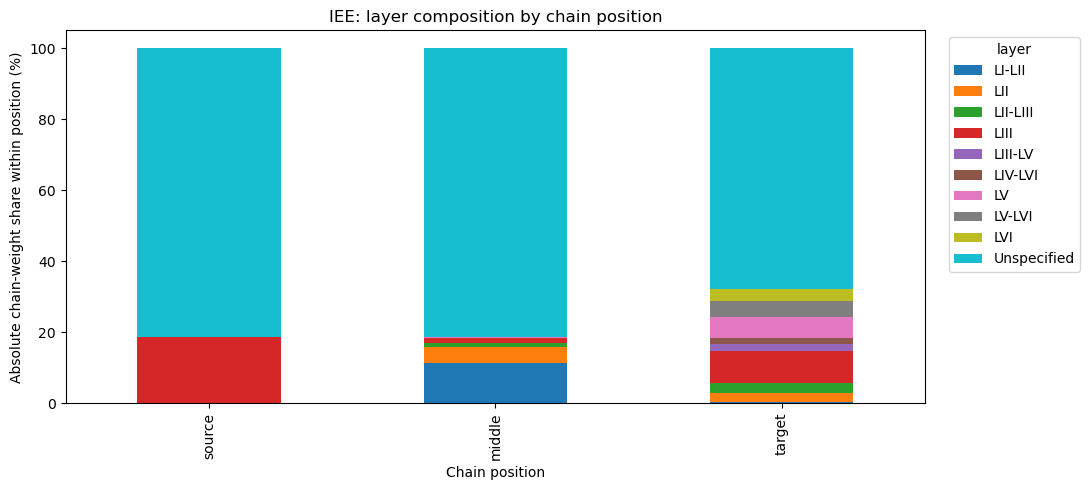

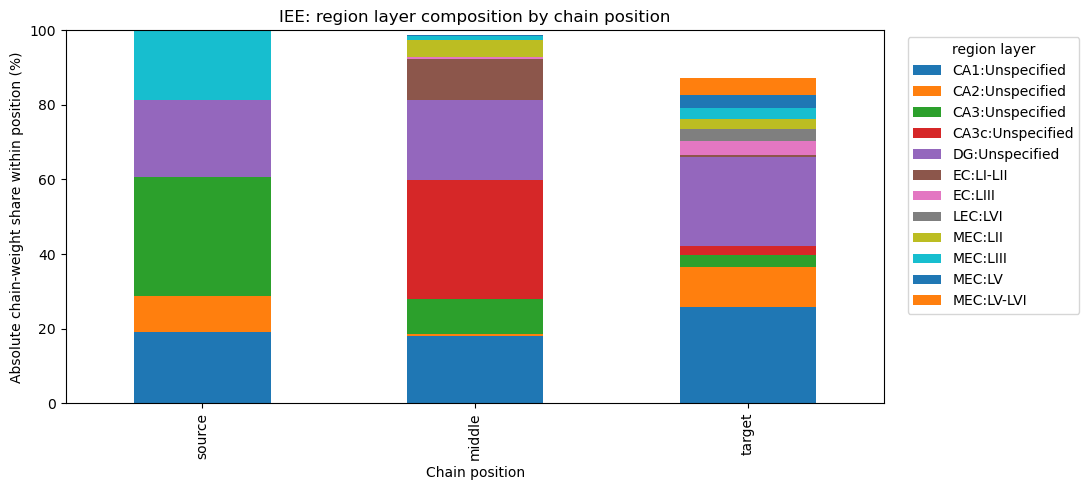

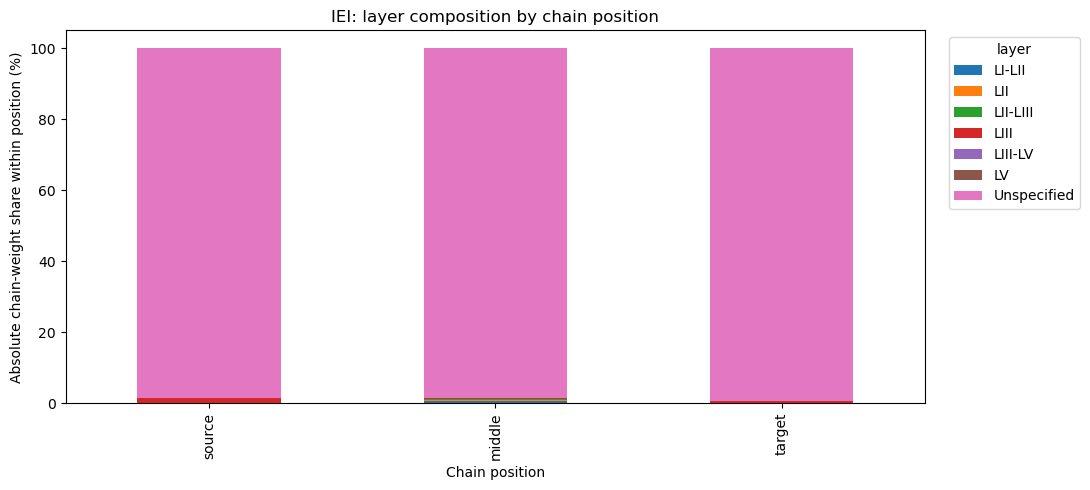

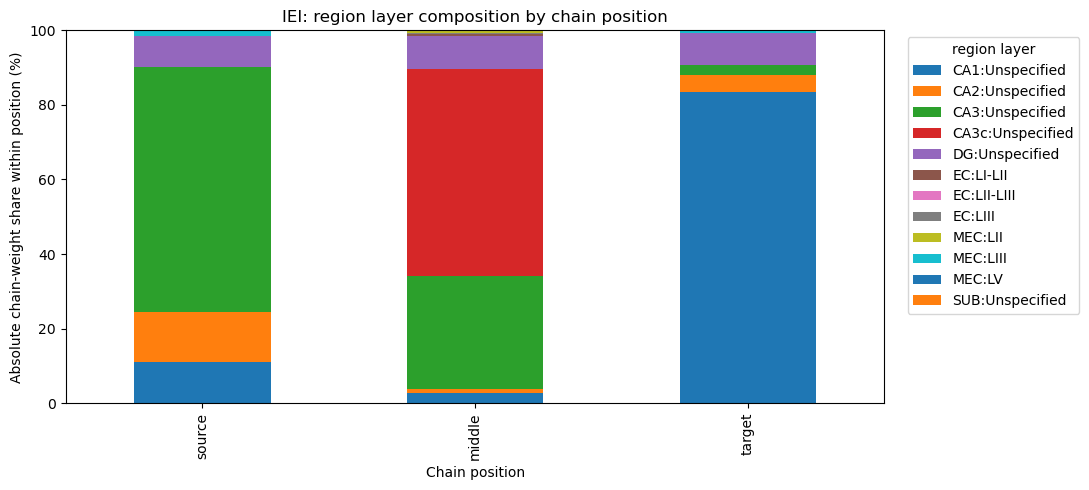

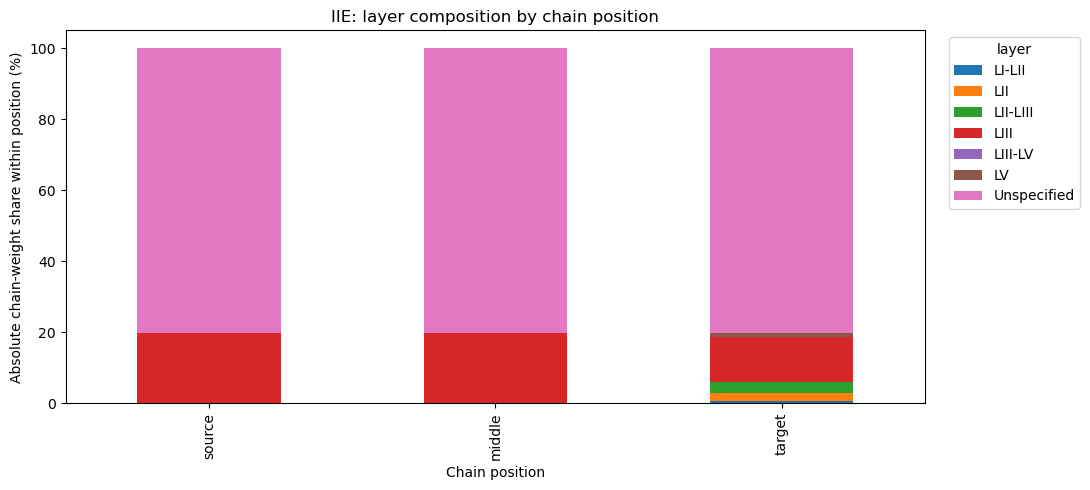

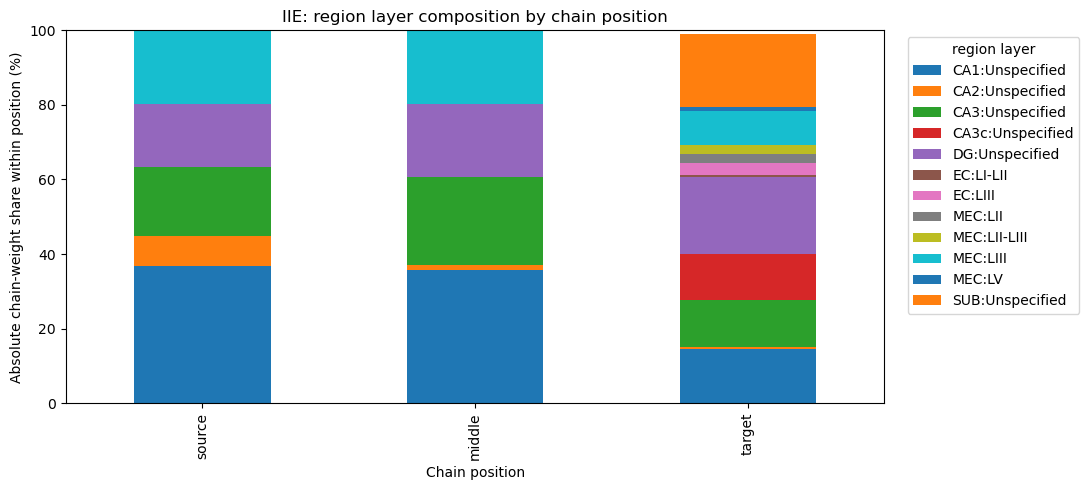

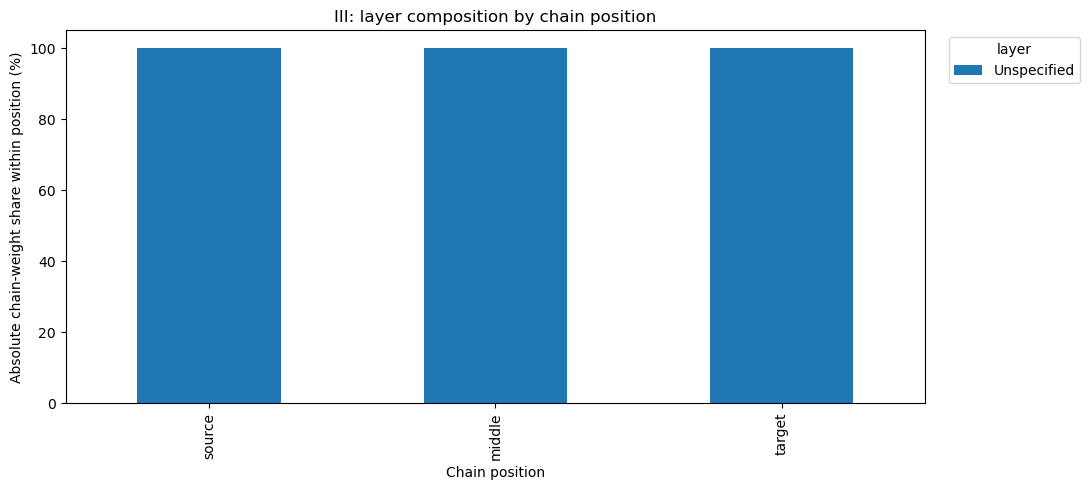

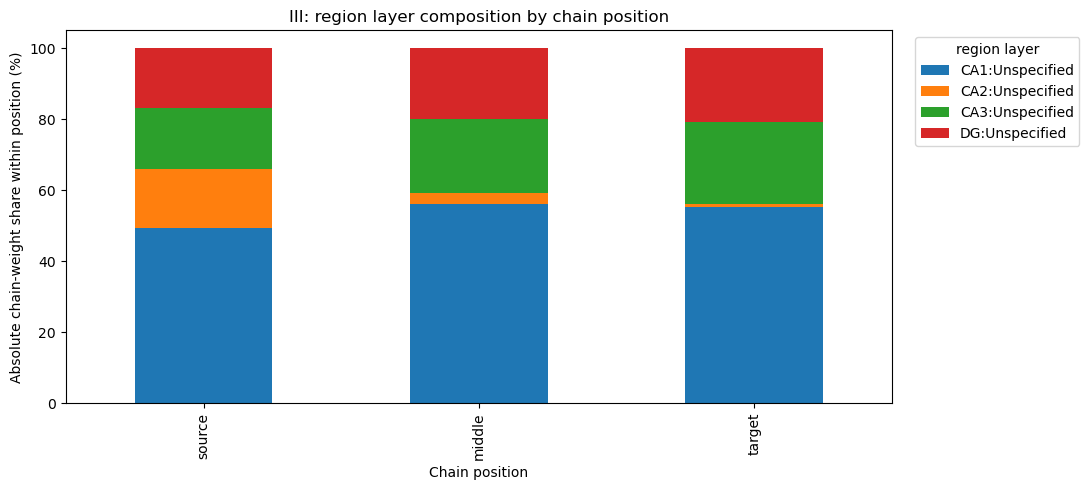

In [22]:

# Position-specific region-layer composition for every observed signature.
if PLOT_EACH_SIGNATURE:
    observed = set(chains["signature"])
    for signature in SIGNATURE_ORDER:
        if signature not in observed:
            continue

        plot_signature_position_composition(
            participation,
            signature,
            "layer",
            top_n=12,
        )
        plot_signature_position_composition(
            participation,
            signature,
            "region_layer",
            top_n=12,
        )


### Interpreting region × layer results

Use these views to separate three different questions:

1. **Region effect:** Is a signature concentrated in DG, CA3, CA1, EC, MEC, SUB, etc.?
2. **Layer effect:** Is it concentrated in superficial or deeper layers independent of region?
3. **Region-layer interaction:** Is a signature specifically concentrated in compartments such as `EC:LI-LII` or `MEC:LIII`?

This is especially useful when the same broad cell class occurs in multiple regions or layers. The collapsed cell-type analysis now removes both region and leading layer notation, while this section preserves layer information explicitly rather than discarding it.


## 9. Region-to-region chain flow

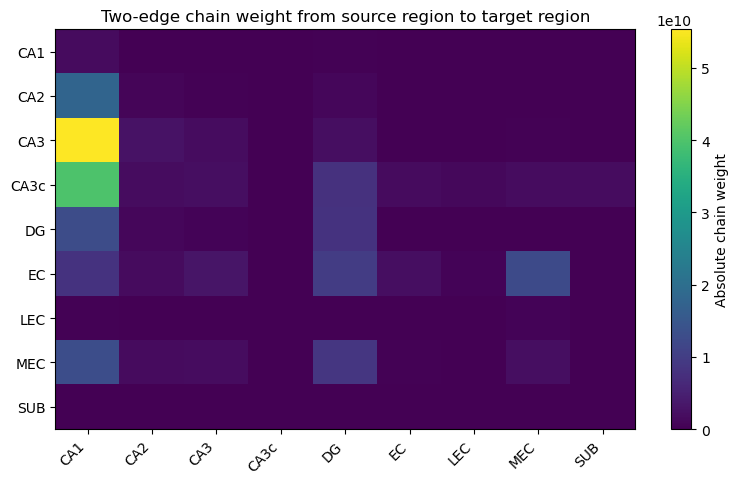

In [23]:

# Collapse each 3-node chain to its source and target regions.
# The middle region is ignored in this particular summary.
region_flow = (
    chains.groupby(["region_1", "region_3"], as_index=False)
    .agg(
        chain_count=("signature", "size"),
        abs_chain_weight=("abs_chain_weight", "sum"),
    )
)

flow_pivot = (
    region_flow.pivot(index="region_1", columns="region_3", values="abs_chain_weight")
    .fillna(0)
)

heatmap_from_pivot(
    flow_pivot,
    "Two-edge chain weight from source region to target region",
    "Absolute chain weight",
    filename="15_region_source_target_flow",
)


## 10. Position-specific composition for every E/I signature

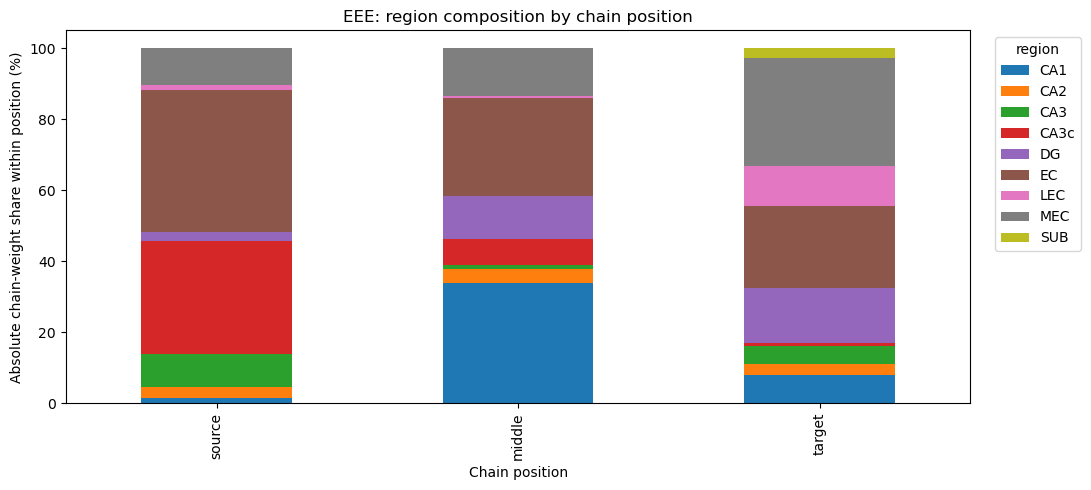

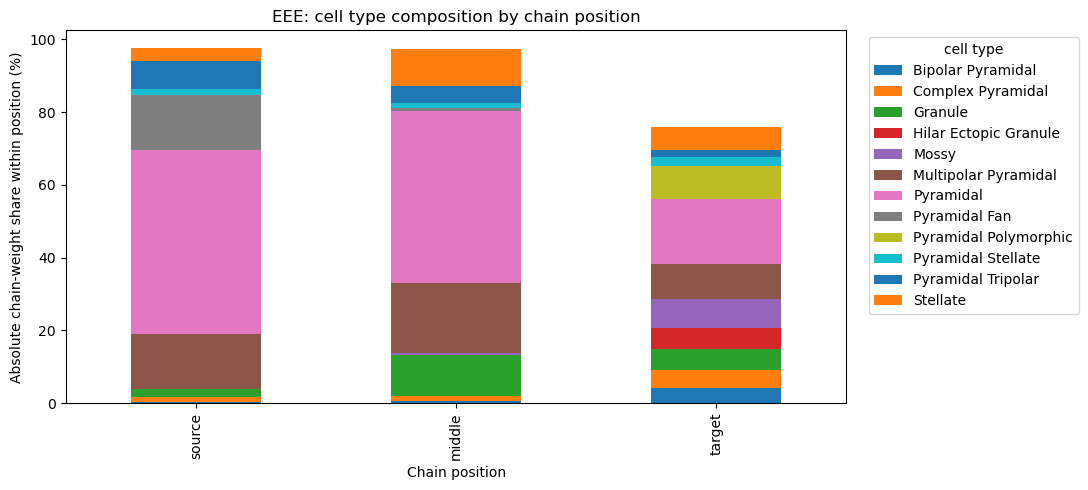

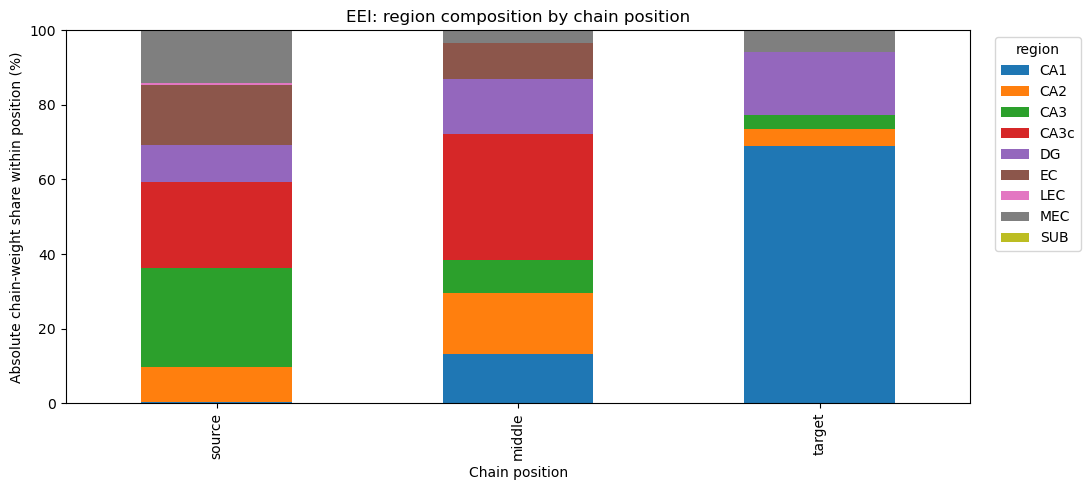

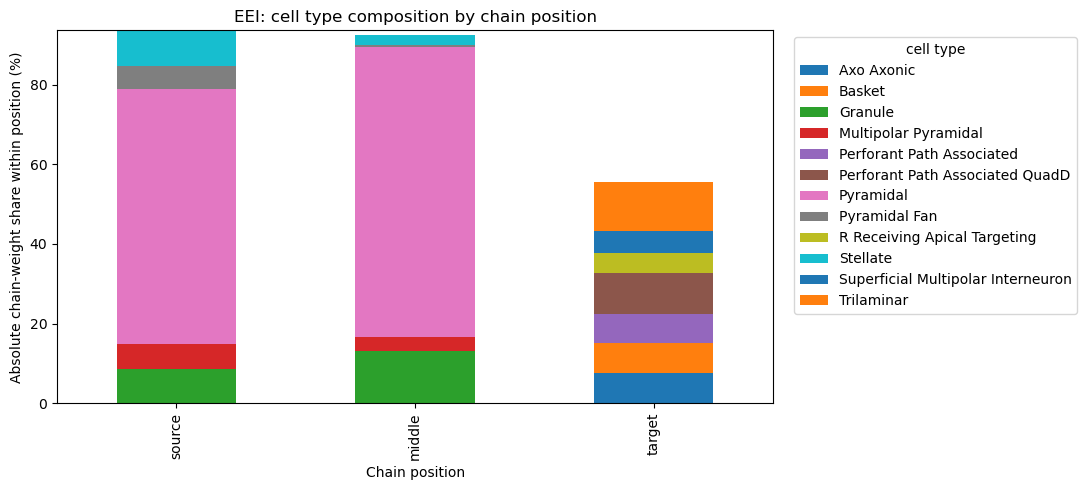

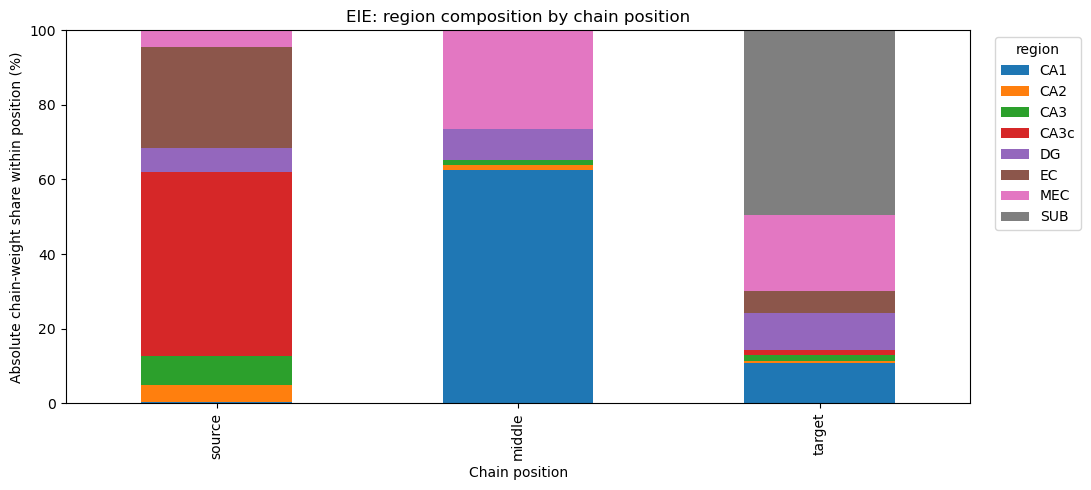

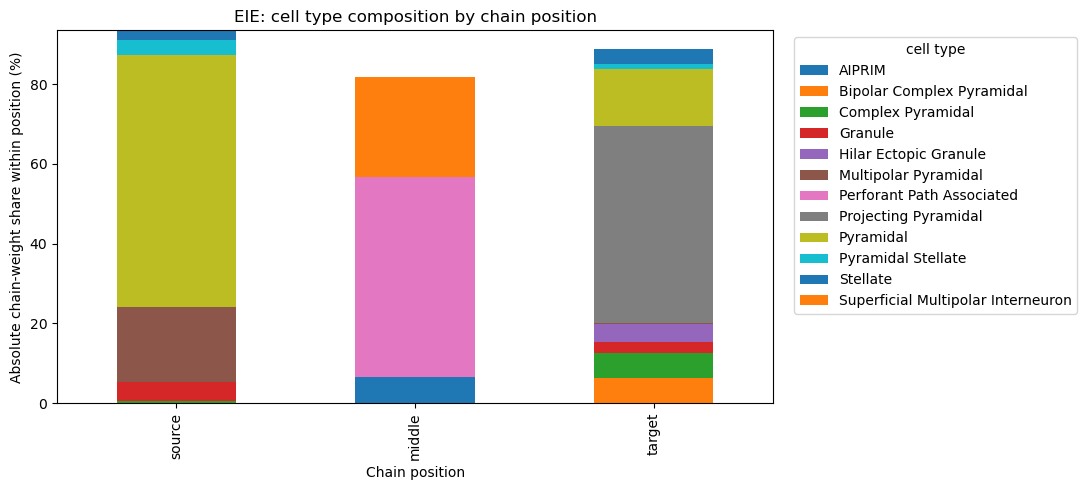

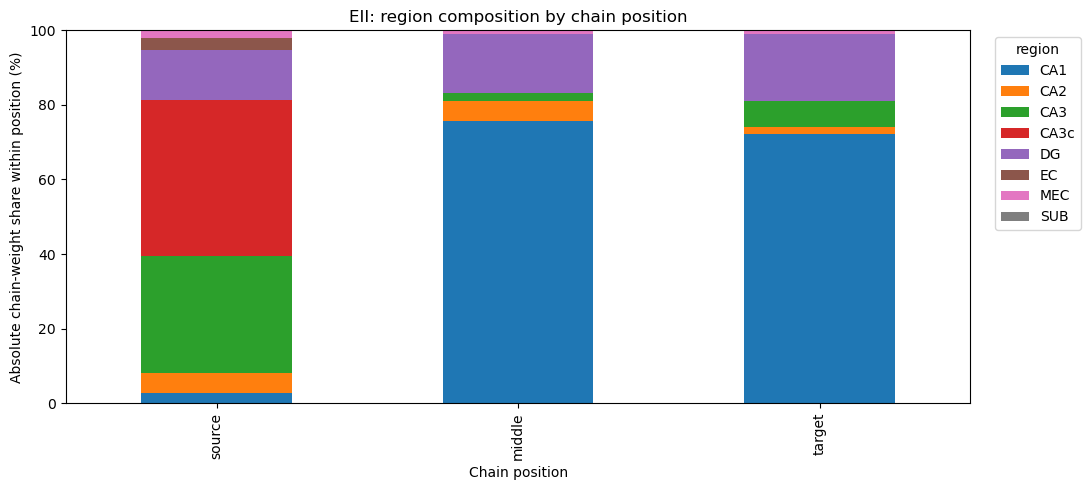

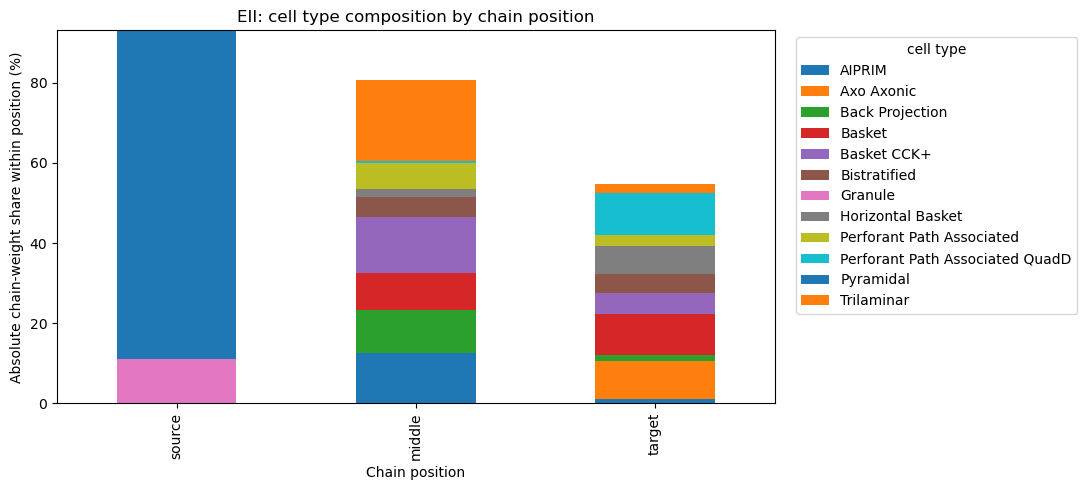

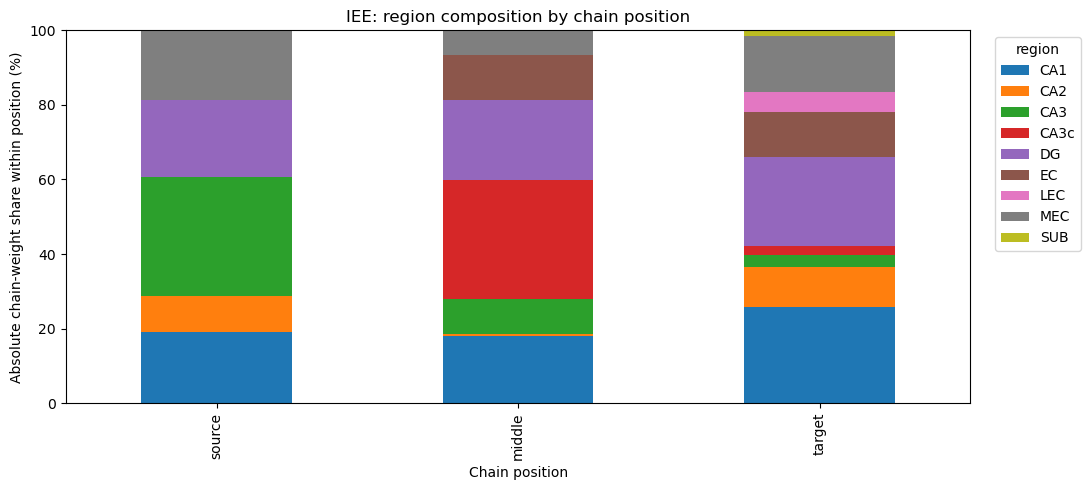

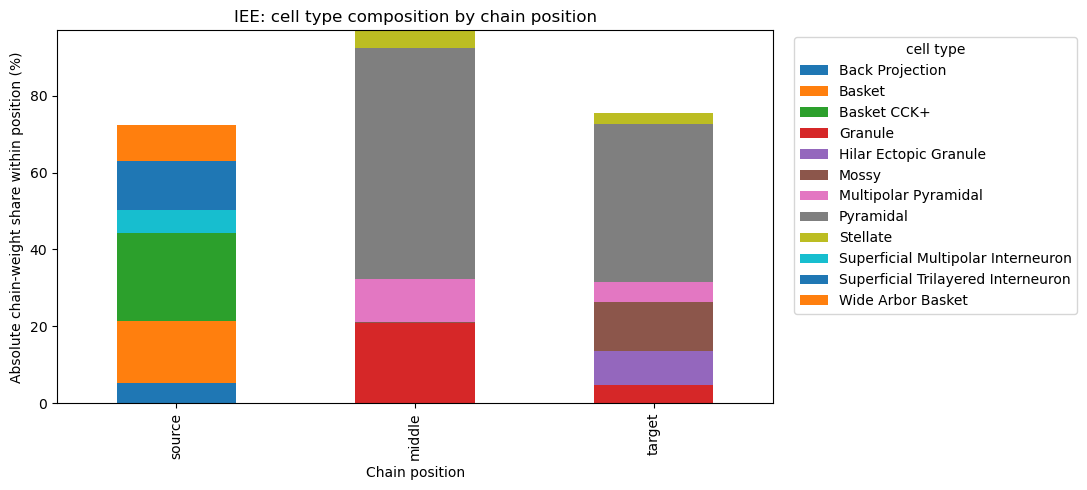

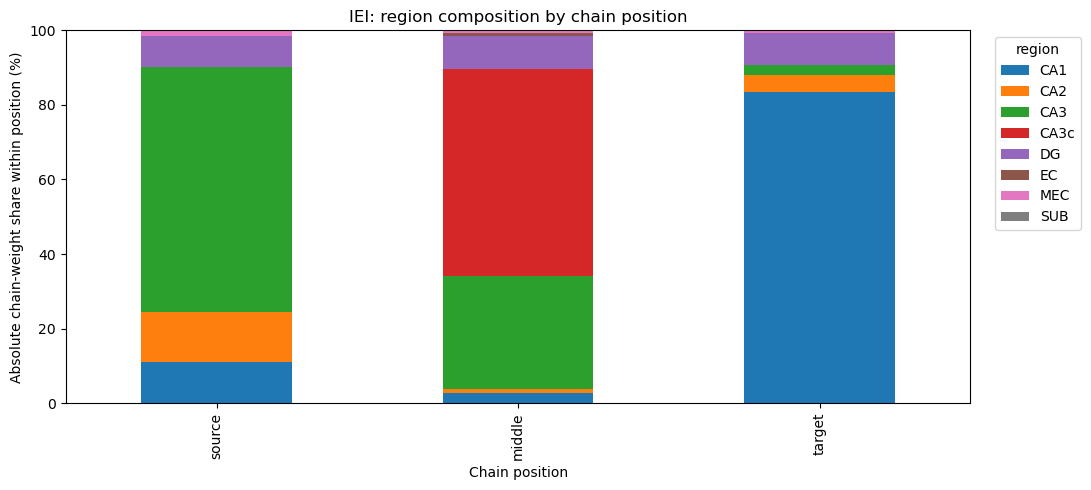

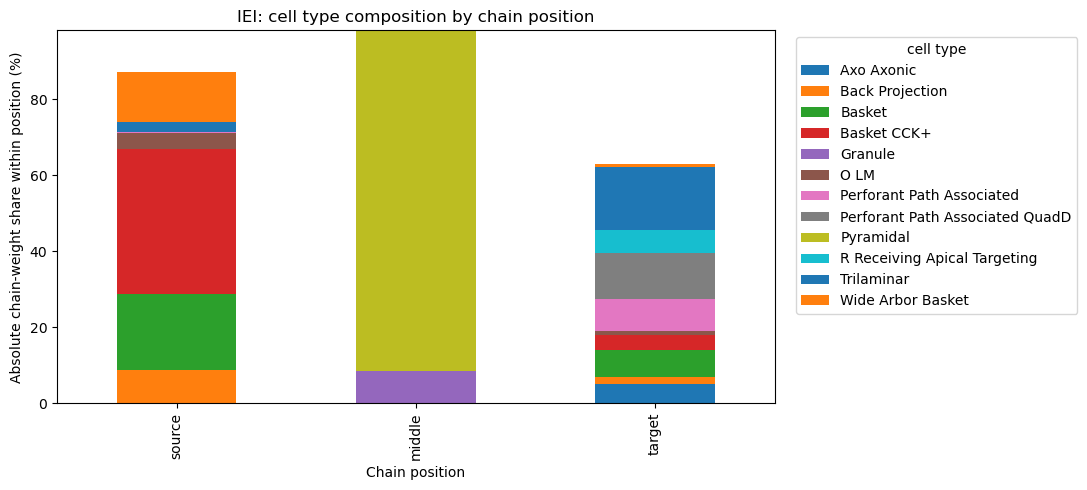

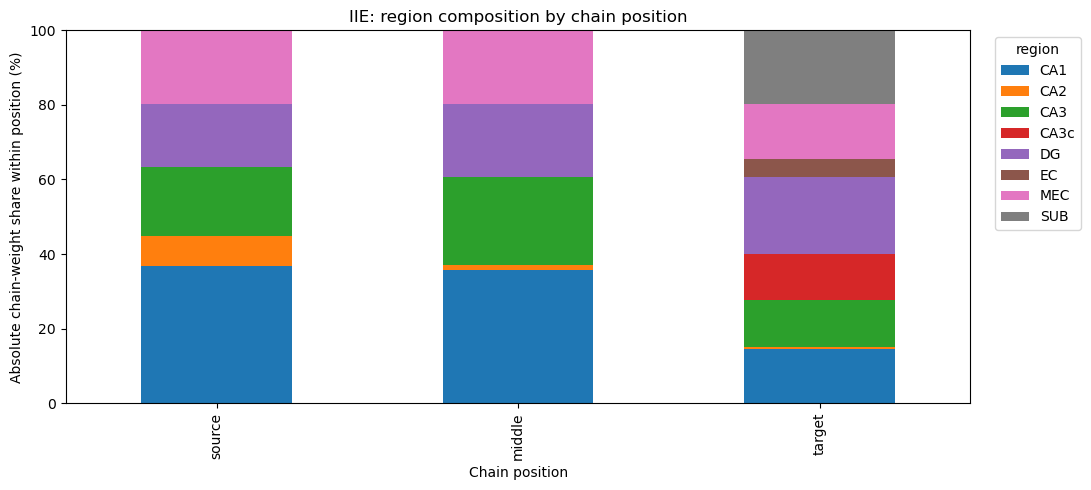

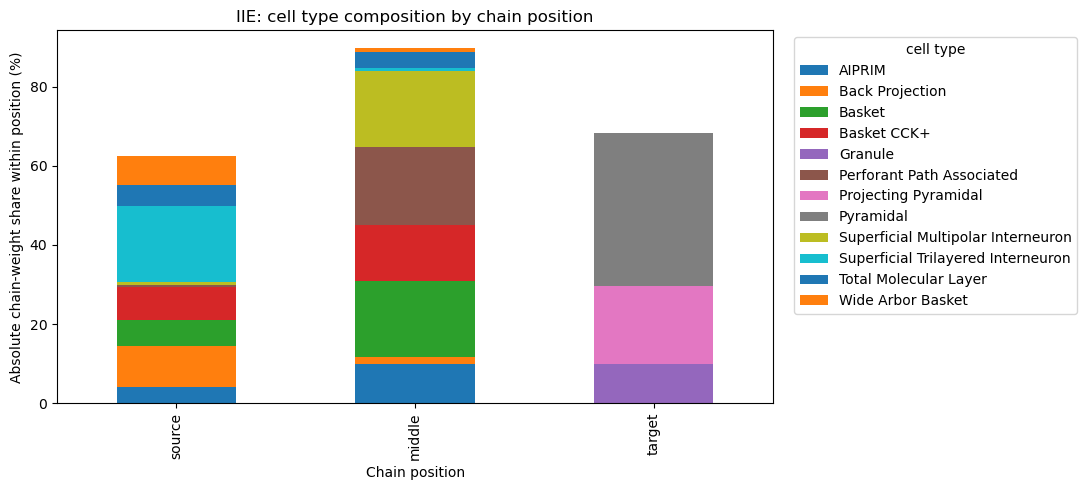

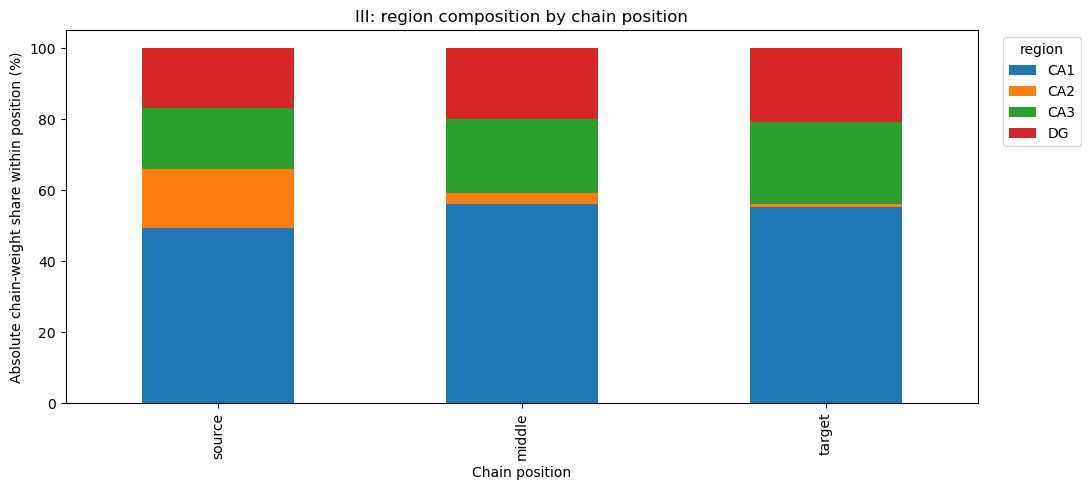

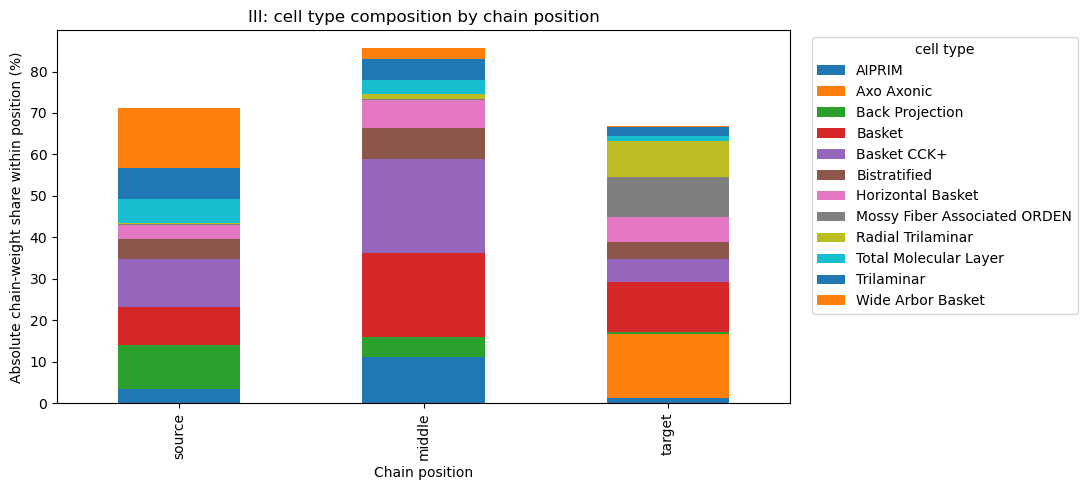

In [24]:

# These plots distinguish source, middle, and target composition.
# Example: for EII, they show which regions/cell types occupy the E source,
# first I middle node, and second I target node.

if PLOT_EACH_SIGNATURE:
    observed = set(chains["signature"])
    for signature in SIGNATURE_ORDER:
        if signature not in observed:
            print(f"{signature}: no observed chains")
            continue

        plot_signature_position_composition(
            participation,
            signature,
            "region",
            top_n=12,
        )
        plot_signature_position_composition(
            participation,
            signature,
            "cell_type",
            top_n=12,
        )


## 11. Drill-down tables for a selected signature

In [25]:

SELECT_SIGNATURE = "EII"

if SELECT_SIGNATURE not in SIGNATURE_ORDER:
    raise ValueError(f"SELECT_SIGNATURE must be one of {SIGNATURE_ORDER}")

selected = chains[chains["signature"] == SELECT_SIGNATURE].copy()

print(f"{SELECT_SIGNATURE} chains: {len(selected):,}")
print(
    f"{SELECT_SIGNATURE} share of all absolute chain weight: "
    f"{sig.set_index('signature').loc[SELECT_SIGNATURE, 'abs_chain_weight_pct']:.2f}%"
)

print("\nTop individual chains:")
display(
    selected.nlargest(25, "abs_chain_weight")[
        [
            "node_pathway", "region_pathway", "cell_type_pathway",
            "w_12", "w_23", "signed_chain_weight",
            "abs_chain_weight", "intensity_geomean"
        ]
    ]
)

print("\nTop regions within signature:")
display(
    sig_region[sig_region["signature"] == SELECT_SIGNATURE]
    .head(25)
)

print("\nTop collapsed cell types within signature:")
display(
    sig_cell[sig_cell["signature"] == SELECT_SIGNATURE]
    .head(25)
)

print("\nTop region pathways within signature:")
display(
    sig_region_paths[sig_region_paths["signature"] == SELECT_SIGNATURE]
    .head(25)
)

print("\nTop cell-type pathways within signature:")
display(
    sig_cell_paths[sig_cell_paths["signature"] == SELECT_SIGNATURE]
    .head(25)
)


EII chains: 4,150
EII share of all absolute chain weight: 9.16%

Top individual chains:


,node_pathway,region_pathway,cell_type_pathway,w_12,w_23,signed_chain_weight,abs_chain_weight,intensity_geomean
14509,CA3 Pyramidal → CA1 Trilaminar → CA1 Perforant...,CA3 → CA1 → CA1,Pyramidal → Trilaminar → Perforant Path Associ...,1.227403e+06,-607.617548,-7.457915e+08,7.457915e+08,27309.184129
16002,CA3c Pyramidal → CA1 Basket CCK+ → CA1 Horizon...,CA3c → CA1 → CA1,Pyramidal → Basket CCK+ → Horizontal Basket,3.490040e+05,-1523.625908,-5.317515e+08,5.317515e+08,23059.737358
16006,CA3c Pyramidal → CA1 Basket CCK+ → CA1 Radial ...,CA3c → CA1 → CA1,Pyramidal → Basket CCK+ → Radial Trilaminar,3.490040e+05,-1509.177757,-5.267090e+08,5.267090e+08,22950.142157
17495,DG Granule → DG AIPRIM → DG HICAP,DG → DG → DG,Granule → AIPRIM → HICAP,2.242495e+05,-2095.507601,-4.699165e+08,4.699165e+08,21677.556495
17493,DG Granule → DG AIPRIM → DG Axo Axonic,DG → DG → DG,Granule → AIPRIM → Axo Axonic,2.242495e+05,-2091.281900,-4.689688e+08,4.689688e+08,21655.688503
16000,CA3c Pyramidal → CA1 Basket CCK+ → CA1 Basket,CA3c → CA1 → CA1,Pyramidal → Basket CCK+ → Basket,3.490040e+05,-1334.263907,-4.656634e+08,4.656634e+08,21579.235328
16183,CA3c Pyramidal → CA1 Perforant Path Associated...,CA3c → CA1 → CA1,Pyramidal → Perforant Path Associated → LMR,7.737279e+05,-393.002849,-3.040773e+08,3.040773e+08,17437.811399
16001,CA3c Pyramidal → CA1 Basket CCK+ → CA1 Bistrat...,CA3c → CA1 → CA1,Pyramidal → Basket CCK+ → Bistratified,3.490040e+05,-744.309499,-2.597670e+08,2.597670e+08,16117.287866
15993,CA3c Pyramidal → CA1 Basket → CA1 Horizontal B...,CA3c → CA1 → CA1,Pyramidal → Basket → Horizontal Basket,3.525306e+05,-730.807386,-2.576320e+08,2.576320e+08,16050.917806
14513,CA3 Pyramidal → CA1 Trilaminar → CA1 Radial Tr...,CA3 → CA1 → CA1,Pyramidal → Trilaminar → Radial Trilaminar,1.227403e+06,-194.863319,-2.391758e+08,2.391758e+08,15465.309615



Top regions within signature:


,signature,region,node_occurrences,unique_populations,abs_chain_weight_allocated,signed_chain_weight_allocated,occurrence_pct_within_signature,weight_pct_within_signature
26,EII,CA1,5921,28,1.071542e+10,-1.071542e+10,47.558233,50.196137
27,EII,DG,2001,14,3.385711e+09,-3.385711e+09,16.072289,15.860284
28,EII,CA3c,627,1,2.988515e+09,-2.988515e+09,5.036145,13.999628
29,EII,CA3,1768,13,2.863509e+09,-2.863509e+09,14.200803,13.414043
30,EII,CA2,1004,5,9.012469e+08,-9.012469e+08,8.064257,4.221870
31,EII,MEC,272,10,2.596523e+08,-2.596523e+08,2.184739,1.216335
32,EII,EC,524,7,2.280013e+08,-2.280013e+08,4.208835,1.068067
33,EII,SUB,333,1,5.045476e+06,-5.045476e+06,2.674699,0.023635



Top collapsed cell types within signature:


,signature,cell_type,node_occurrences,unique_populations,abs_chain_weight_allocated,signed_chain_weight_allocated,occurrence_pct_within_signature,weight_pct_within_signature
145,EII,Pyramidal,2434,6,5.849276e+09,-5.849276e+09,19.550201,27.400794
146,EII,Trilaminar,318,2,1.603944e+09,-1.603944e+09,2.554217,7.513639
147,EII,Basket,472,4,1.370544e+09,-1.370544e+09,3.791165,6.420283
148,EII,Basket CCK+,295,2,1.368435e+09,-1.368435e+09,2.369478,6.410400
149,EII,AIPRIM,159,1,9.780455e+08,-9.780455e+08,1.277108,4.581631
150,EII,Back Projection,339,1,8.615818e+08,-8.615818e+08,2.722892,4.036060
151,EII,Granule,257,2,7.774445e+08,-7.774445e+08,2.064257,3.641920
152,EII,Perforant Path Associated QuadD,209,1,7.612248e+08,-7.612248e+08,1.678715,3.565940
153,EII,Bistratified,381,2,7.135377e+08,-7.135377e+08,3.060241,3.342551
154,EII,Axo Axonic,340,3,6.790113e+08,-6.790113e+08,2.730924,3.180813



Top region pathways within signature:


,signature,region_pathway,chain_count,abs_chain_weight,signed_chain_weight,weight_pct_within_signature,count_pct_within_signature
317,EII,CA3c → CA1 → CA1,377,7.863461e+09,-7.863461e+09,36.836197,9.084337
318,EII,CA3 → CA1 → CA1,377,5.475338e+09,-5.475338e+09,25.649091,9.084337
319,EII,DG → DG → DG,208,2.591580e+09,-2.591580e+09,12.140196,5.012048
320,EII,CA2 → CA1 → CA1,377,7.060249e+08,-7.060249e+08,3.307357,9.084337
321,EII,CA3 → CA1 → CA3,11,5.858470e+08,-5.858470e+08,2.744387,0.265060
322,EII,CA1 → CA1 → CA1,594,5.075407e+08,-5.075407e+08,2.377563,14.313253
323,EII,EC → CA1 → CA1,348,3.635150e+08,-3.635150e+08,1.702878,8.385542
324,EII,CA3c → DG → DG,52,2.604429e+08,-2.604429e+08,1.220039,1.253012
325,EII,CA2 → DG → DG,52,2.373019e+08,-2.373019e+08,1.111635,1.253012
326,EII,CA3c → CA1 → DG,16,2.127257e+08,-2.127257e+08,0.996509,0.385542



Top cell-type pathways within signature:


,signature,cell_type_pathway,chain_count,abs_chain_weight,signed_chain_weight,weight_pct_within_signature,count_pct_within_signature
4802,EII,Pyramidal → Trilaminar → Perforant Path Associ...,7,9.519075e+08,-9.519075e+08,4.459188,0.168675
4803,EII,Pyramidal → Basket CCK+ → Horizontal Basket,5,5.892685e+08,-5.892685e+08,2.760415,0.120482
4804,EII,Pyramidal → Basket CCK+ → Radial Trilaminar,5,5.836806e+08,-5.836806e+08,2.734238,0.120482
4805,EII,Pyramidal → Basket CCK+ → Basket,8,5.633517e+08,-5.633517e+08,2.639008,0.192771
4806,EII,Granule → AIPRIM → HICAP,1,4.699165e+08,-4.699165e+08,2.201313,0.024096
4807,EII,Granule → AIPRIM → Axo Axonic,1,4.689688e+08,-4.689688e+08,2.196874,0.024096
4808,EII,Pyramidal → Perforant Path Associated → LMR,4,3.468930e+08,-3.468930e+08,1.625012,0.096386
4809,EII,Pyramidal → Trilaminar → Radial Trilaminar,7,3.051906e+08,-3.051906e+08,1.429658,0.168675
4810,EII,Pyramidal → Basket → Horizontal Basket,5,3.030530e+08,-3.030530e+08,1.419645,0.120482
4811,EII,Pyramidal → Trilaminar → Basket,10,3.018567e+08,-3.018567e+08,1.414040,0.240964


## 12. Compare count share with weight share

,signature,chain_count_pct,abs_chain_weight_pct,weight_minus_count_pct_points,mean_intensity
1,EEI,10.486143,77.042547,66.556404,3519.691382
2,EIE,4.340693,1.566576,-2.774117,632.706835
4,IEE,4.415594,0.166318,-4.249275,296.829190
3,EII,14.801869,9.155308,-5.646561,1038.903213
6,IIE,6.437921,0.009545,-6.428376,47.820013
0,EEE,15.065806,7.917304,-7.148502,789.607148
5,IEI,11.620359,4.070406,-7.549953,717.542803
7,III,32.831615,0.071996,-32.759619,65.752376


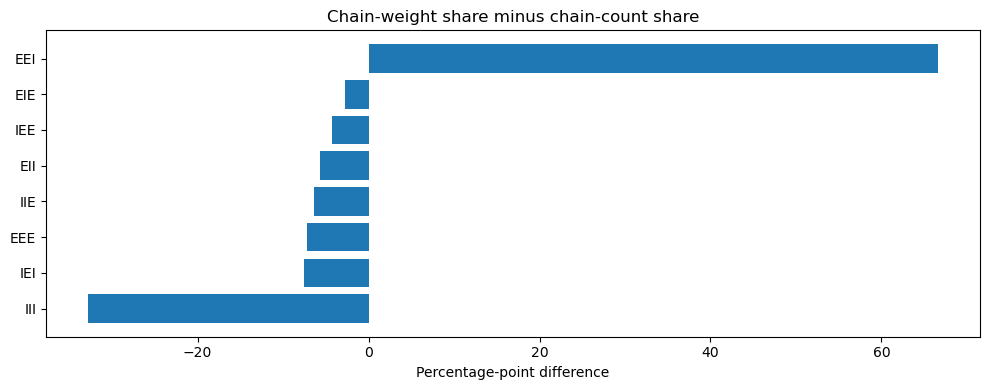

In [26]:

# Positive values indicate a signature carries more chain weight than expected
# from its prevalence alone; negative values indicate the reverse.
sig_compare = sig.copy()
sig_compare["weight_minus_count_pct_points"] = (
    sig_compare["abs_chain_weight_pct"] - sig_compare["chain_count_pct"]
)
sig_compare = sig_compare.sort_values("weight_minus_count_pct_points", ascending=False)

display(
    sig_compare[
        [
            "signature",
            "chain_count_pct",
            "abs_chain_weight_pct",
            "weight_minus_count_pct_points",
            "mean_intensity",
        ]
    ]
)

barh(
    sig_compare,
    "signature",
    "weight_minus_count_pct_points",
    "Chain-weight share minus chain-count share",
    "Percentage-point difference",
    filename="16_signature_weight_minus_count",
)


## 13. Export all analysis tables

In [27]:

edge_class_summary.to_csv(OUTPUT_DIR / "edge_class_summary.csv", index=False)
nodes.to_csv(OUTPUT_DIR / "node_metadata.csv", index=False)
sig_compare.to_csv(OUTPUT_DIR / "ei_signature_count_vs_weight.csv", index=False)
region_flow.to_csv(OUTPUT_DIR / "region_source_target_flow.csv", index=False)

if EXPORT_CHAIN_TABLE:
    chains.to_csv(OUTPUT_DIR / "all_3node_chains.csv", index=False)
    participation.to_csv(OUTPUT_DIR / "all_chain_node_participation.csv", index=False)

print("Exported summary files:")
for p in sorted(OUTPUT_DIR.glob("*.csv")):
    print(" -", p.name)

if SAVE_FIGURES:
    print(f"\nSaved figures: {len(list(FIG_DIR.glob('*.png')))}")
    print("Figure directory:", FIG_DIR.resolve())


Exported summary files:
 - cell_type_composition_by_signature.csv
 - cell_type_participation_overall.csv
 - cell_type_pathway_summary.csv
 - cell_type_pathways_by_signature.csv
 - edge_class_summary.csv
 - ei_signature_count_vs_weight.csv
 - ei_signature_summary.csv
 - layer_composition_by_signature.csv
 - layer_participation_overall.csv
 - layer_pathway_summary.csv
 - node_metadata.csv
 - region_composition_by_signature.csv
 - region_layer_composition_by_signature.csv
 - region_layer_participation_overall.csv
 - region_layer_pathway_summary.csv
 - region_layer_pathways_by_signature.csv
 - region_participation_overall.csv
 - region_pathway_summary.csv
 - region_pathways_by_signature.csv
 - region_source_target_flow.csv

Saved figures: 55
Figure directory: C:\Users\ranic\Documents\GitHub\AscoliLab\inhib_modulation\chain_eda_outputs\figures



## 13. Suggested interpretation sequence

1. **Start with `ei_signature_summary.csv`.**  
   Identify signatures that are common by count versus dominant by weight.

2. **Compare count share and weight share.**  
   A large positive `weight_minus_count_pct_points` indicates a signature is disproportionately strong.

3. **Inspect the region heatmap.**  
   This shows whether a signature is concentrated in DG, CA3, CA1, EC/MEC, SUB, or another anatomical compartment.

4. **Inspect the collapsed cell-type heatmap.**  
   This determines whether signatures are driven by recurring cell classes regardless of anatomical region.

5. **Use position-specific plots.**  
   These distinguish whether a region or cell type appears mainly as the chain source, intermediary, or target.

6. **Inspect top region and cell-type pathways.**  
   This moves from composition to actual ordered pathways.

7. **Drill into individual high-weight chains.**  
   Set `SELECT_SIGNATURE` to signatures such as `EII`, `IEI`, or `EEI` and inspect the strongest node-level chains.

### Important interpretation note

This is a **chain/path analysis**, not an induced-triad census. A chain `A → B → C` is counted whenever those two ordered edges exist, even if other edges among A, B, and C also exist. That makes this analysis appropriate for questions about sequential coupling and E/I routing. If the question changes to *which complete 3-node directed motif is present*, use the separate directed-triad / Rees-style motif census workflow.
